# SkinSense: Skin-Type Dataset Preparation (Stages 0 to 2)

This notebook cleans the skin-type dataset before any training. Nothing is deleted from the input: every image gets a row in a **manifest** (CSV), and each stage marks rows as `keep` or `drop` with a reason.

| Stage | What it does |
|---|---|
| 0 | Inventory: one row per image (class, source, size, file hash) |
| 1 | Duplicates: drop pre-augmented copies, exact copies, Roboflow siblings, near-duplicates (incl. mirrored), and cross-class conflicts |
| 2 | Face and quality gate: same checks as the app's photo validator; saves landmarks for Stage 3 |

**Before running:** turn Internet ON (needed for `pip install`), set `DATA_DIR` in the config cell. No GPU is needed for this notebook. To keep the outputs, use **Save Version > Save & Run All**.

Outputs in `/kaggle/working/skin_type_prep/`: `manifest_stage0.csv`, `manifest_stage1.csv`, `manifest_stage2.csv`, `landmarks.npz`.

## Stage 0

In [1]:
# Main kernel (Kaggle's Python) does NOT use mediapipe. MediaPipe runs in a separate
# Python 3.11 env identical to the backend: mediapipe 0.10.21 + numpy<2.
import sys
print("Kaggle kernel Python:", sys.version.split()[0])

!pip install -q imagehash uv
!python -m uv python install 3.11
!python -m uv venv -q --allow-existing /tmp/mp311 --python 3.11
!python -m uv pip install -q --python /tmp/mp311/bin/python "mediapipe==0.10.21" "numpy<2" pandas pillow
!MPLBACKEND=Agg /tmp/mp311/bin/python -c "import sys, numpy, mediapipe as mp; print('side env: Python', sys.version.split()[0], '| numpy', numpy.__version__, '| mediapipe', mp.__version__, '| mp.solutions:', hasattr(mp, 'solutions'))"

Kaggle kernel Python: 3.13.15
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 76.3 MB/s eta 0:00:00:00:0100:01
Installed Python 3.11.18 in 1.11s
 + cpython-3.11.18-linux-x86_64-gnu (python3.11)
side env: Python 3.11.18 | numpy 1.26.4 | mediapipe 0.10.21 | mp.solutions: True


In [2]:
import hashlib
import math
import re
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm

print("numpy", np.__version__, "| pandas", pd.__version__)

DATA_DIR = Path("/kaggle/input/datasets/himantveerkaur/skintypedataset")
WORK_DIR = Path("/kaggle/working/skin_type_prep")
WORK_DIR.mkdir(parents=True, exist_ok=True)
SIDE_PY = "/tmp/mp311/bin/python"                  # Python 3.11 env with mediapipe 0.10.21

CLASSES = ["dry", "normal", "oily"]              # matched against folder names, case-insensitive
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Stage 1
PHASH_MAX_DIST = 6         # max Hamming distance (out of 64 bits) to call two images near-duplicates

# Stage 2: based on the app's photo validator (code/backend/services/photo_validation.py)
DETECT_MAX_SIDE = 640      # images are downscaled to this before detection, like the app
MIN_FACE_WIDTH_PX = 160    # measured in the ORIGINAL image
MAX_YAW_DEG = 40.0         # looser than the app's 25: the estimate overstates yaw, mild turns are still usable
MIN_BLUR_SCORE = 10.0
MIN_BRIGHTNESS, MAX_BRIGHTNESS = 45.0, 215.0
# A face touching the frame edge is fine (Roboflow images are tight crops).
# An image is dropped only if one of these skin landmarks is outside the frame.
KEY_LANDMARKS = {"forehead": 151, "nose": 4, "left_cheek": 50, "right_cheek": 280}

assert DATA_DIR.exists(), f"DATA_DIR not found: {DATA_DIR}"

numpy 2.1.3 | pandas 2.3.3


In [3]:
# Helpers shared by all stages

def load_rgb(path):
    # Open an image, apply phone EXIF rotation, return RGB (or None if unreadable).
    try:
        with Image.open(path) as im:
            return ImageOps.exif_transpose(im).convert("RGB")
    except Exception:
        return None


def drop(mask, reason):
    # Mark rows as dropped (never deletes them). Only rows still kept are affected.
    m = mask.fillna(False).astype(bool) & (df["status"] == "keep")
    df.loc[m, "status"] = "drop"
    df.loc[m, "drop_reason"] = reason
    return int(m.sum())


def funnel(stage):
    kept = df["status"].eq("keep")
    t = (df.assign(kept=kept).groupby(df["label"].fillna("(none)"))["kept"]
           .agg(total="size", kept="sum"))
    t.loc["ALL"] = t.sum()
    print(f"=== after {stage} ===")
    display(t)
    d = df[df["status"] == "drop"]
    if len(d):
        display(d.groupby(["drop_reason", d["label"].fillna("(none)")]).size()
                 .unstack(fill_value=0))


def show_images(ids, titles, ncols=4, size=2.6, suptitle=None):
    if len(ids) == 0:
        print(f"{suptitle or 'images'}: none")
        return
    nrows = math.ceil(len(ids) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.4))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, i, t in zip(np.ravel(axes), ids, titles):
        img = load_rgb(df.at[i, "path"])
        if img is not None:
            img.thumbnail((300, 300))
            ax.imshow(img)
        ax.set_title(t, fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()

In [4]:
RF_RE = re.compile(r"^(?P<base>.+?)[._](?:jpe?g|png|webp|bmp)[._]rf[._](?P<rfhash>[0-9a-f]{32})$", re.I)
AUG_PREFIX_RE = re.compile(
    r"^augmented_(?:(?:rotation|flip|zoom|crop|shear|blur|noise|bright\w*|contrast|exposure|hue|saturation)\d*_)?",
    re.I)


def class_from_path(p):
    # Nearest parent folder whose name contains exactly one class name.
    for part in reversed(p.relative_to(DATA_DIR).parts[:-1]):
        hits = [c for c in CLASSES if c in part.lower()]
        if len(hits) == 1:
            return hits[0]
    return None


def parse_name(stem):
    m = RF_RE.match(stem)
    source = "roboflow" if m else "web"
    base = m.group("base") if m else stem
    augmented = base.lower().startswith("augmented")
    if augmented:
        base = AUG_PREFIX_RE.sub("", base)
    return source, base, augmented


def file_info(p):
    data = p.read_bytes()
    info = {"md5": hashlib.md5(data).hexdigest(), "file_kb": round(len(data) / 1024, 1)}
    try:
        with Image.open(p) as im:
            w, h = im.size
            if im.getexif().get(274, 1) in (5, 6, 7, 8):   # EXIF says rotated 90 degrees
                w, h = h, w
            im.verify()
        info.update(readable=True, width=w, height=h)
    except Exception:
        info.update(readable=False, width=np.nan, height=np.nan)
    return info


files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)
rows = []
for k, p in enumerate(tqdm(files, desc="Stage 0")):
    source, base, augmented = parse_name(p.stem)
    rows.append({"img_id": f"img_{k:06d}", "path": str(p), "rel": str(p.relative_to(DATA_DIR)),
                 "label": class_from_path(p), "source": source, "base": base,
                 "augmented": augmented, **file_info(p)})

df = pd.DataFrame(rows)
df["status"] = "keep"
df["drop_reason"] = ""
drop(df["label"].isna(), "no_class_folder")
drop(~df["readable"], "unreadable")

print(f"{len(df)} image files found under {DATA_DIR}")
display(pd.crosstab(df["label"].fillna("(none)"), df["source"], margins=True))
display(pd.crosstab(df["label"].fillna("(none)"), df["augmented"].map({True: "augmented", False: "original"}),
                    margins=True))

ok = df[df["readable"]].assign(square=lambda d: d["width"] == d["height"])
print("Image sizes by class and source (a big difference between classes is a shortcut risk):")
display(ok.groupby(["label", "source"]).agg(n=("path", "size"), median_w=("width", "median"),
                                             median_h=("height", "median"), square_share=("square", "mean"))
          .round(2))

df.to_csv(WORK_DIR / "manifest_stage0.csv", index=False)
funnel("Stage 0")

Stage 0:   0%|          | 0/714 [00:00<?, ?it/s]

714 image files found under /kaggle/input/datasets/himantveerkaur/skintypedataset


source,web,All
label,,
dry,151,151
normal,217,217
oily,346,346
All,714,714


augmented,original,All
label,,
dry,151,151
normal,217,217
oily,346,346
All,714,714


Image sizes by class and source (a big difference between classes is a shortcut risk):


,,n,median_w,median_h,square_share
label,source,,,,
dry,web,150,640.0,640.0,0.95
normal,web,217,640.0,640.0,1.00
oily,web,346,736.0,981.0,0.17


=== after Stage 0 ===


,total,kept
label,,
dry,151,150
normal,217,217
oily,346,346
ALL,714,713


label,dry
drop_reason,
unreadable,1


## Stage 1

Dropped 0 pre-augmented files


Stage 1 hashing:   0%|          | 0/713 [00:00<?, ?it/s]

28 groups with more than one image | 26 duplicates dropped | 4 images dropped as cross-class label conflicts


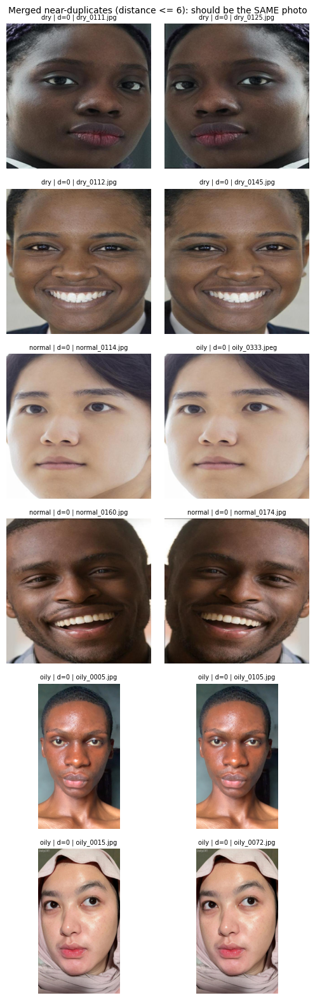

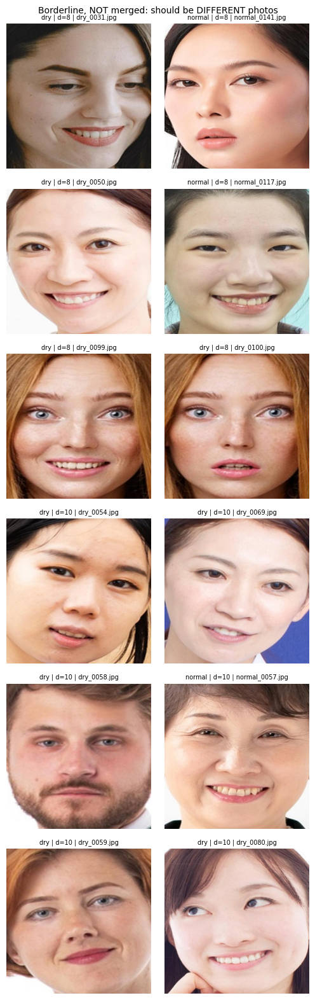

=== after Stage 1 ===


,total,kept
label,,
dry,151,147
normal,217,212
oily,346,324
ALL,714,683


label,dry,normal,oily
drop_reason,,,
duplicate,2,3,21
label_conflict,1,2,1
unreadable,1,0,0


In [5]:
n_aug = drop(df["augmented"], "pre_augmented")
print(f"Dropped {n_aug} pre-augmented files")

# Perceptual hashes of each kept image and of its mirror image
ph, ph_mirror = {}, {}
for i in tqdm(df.index[df["status"] == "keep"], desc="Stage 1 hashing"):
    img = load_rgb(df.at[i, "path"])
    if img is None:
        drop(pd.Series(df.index == i, index=df.index), "unreadable")
        continue
    img.thumbnail((512, 512))
    ph[i] = int(str(imagehash.phash(img)), 16)
    ph_mirror[i] = int(str(imagehash.phash(ImageOps.mirror(img))), 16)
df["phash"] = pd.Series({i: f"{v:016x}" for i, v in ph.items()})

ids = np.array(sorted(ph))
H = np.array([ph[i] for i in ids], dtype=np.uint64)
HM = np.array([ph_mirror[i] for i in ids], dtype=np.uint64)


def hamming(a, B):
    x = np.bitwise_xor(a, B)
    return np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)


# Union-find over image ids
parent = {i: i for i in ids}
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

kept = df.loc[ids]
for _, grp in kept.groupby("md5"):                                   # identical files
    for j in grp.index[1:]:
        union(grp.index[0], j)
for _, grp in kept[kept["source"] == "roboflow"].groupby("base"):    # Roboflow siblings
    for j in grp.index[1:]:
        union(grp.index[0], j)

near_pairs, borderline = [], []
for a in range(len(ids)):
    if a + 1 == len(ids):
        break
    d = np.minimum(hamming(H[a], H[a + 1:]), hamming(H[a], HM[a + 1:]))
    for off in np.nonzero(d <= PHASH_MAX_DIST + 4)[0]:
        b = a + 1 + off
        pair = (ids[a], ids[b], int(d[off]))
        if d[off] <= PHASH_MAX_DIST:
            union(ids[a], ids[b])
            near_pairs.append(pair)
        else:
            borderline.append(pair)

df["dup_group"] = pd.Series({i: f"grp_{find(i)}" for i in ids})
groups = df.loc[ids].groupby("dup_group")
conflicts = dups = 0
for _, grp in groups:
    if len(grp) == 1:
        continue
    if grp["label"].nunique() > 1:
        df.loc[grp.index, ["status", "drop_reason"]] = ["drop", "label_conflict"]
        conflicts += len(grp)
    else:
        best = (grp["width"] * grp["height"]).idxmax()
        rest = grp.index.drop(best)
        df.loc[rest, ["status", "drop_reason"]] = ["drop", "duplicate"]
        dups += len(rest)

multi = sum(len(g) > 1 for _, g in groups)
print(f"{multi} groups with more than one image | {dups} duplicates dropped | "
      f"{conflicts} images dropped as cross-class label conflicts")

def pair_gallery(pairs, title, n=6):
    pairs = sorted(pairs, key=lambda t: t[2])[:n]
    show_images([x for a, b, _ in pairs for x in (a, b)],
                [f"{df.at[x, 'label']} | d={dist} | {Path(df.at[x, 'path']).name[:24]}"
                 for a, b, dist in pairs for x in (a, b)],
                ncols=2, suptitle=title)

pair_gallery(near_pairs, f"Merged near-duplicates (distance <= {PHASH_MAX_DIST}): should be the SAME photo")
pair_gallery(borderline, "Borderline, NOT merged: should be DIFFERENT photos")

df.to_csv(WORK_DIR / "manifest_stage1.csv", index=False)
funnel("Stage 1")

## Stage 2

In [6]:
%%writefile /kaggle/working/stage2_worker.py
# Stage 2 worker. Runs in the Python 3.11 env (mediapipe 0.10.21, same as the backend).
# Reads manifest_stage1.csv, writes stage2_metrics.csv and landmarks_all.npz.
import json
import math
import sys
from pathlib import Path

import mediapipe as mp
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

cfg = json.loads(Path(sys.argv[1]).read_text())
work = Path(cfg["work_dir"])
NOSE, CHEEK_A, CHEEK_B = 1, 234, 454
KEY = cfg["key_landmarks"]

mesh = mp.solutions.face_mesh.FaceMesh(static_image_mode=True, max_num_faces=2,
                                       refine_landmarks=False, min_detection_confidence=0.5)


def load_rgb(path):
    try:
        with Image.open(path) as im:
            return ImageOps.exif_transpose(im).convert("RGB")
    except Exception:
        return None


def yaw_deg(lm):
    nose, a, b = lm[NOSE, 0], lm[CHEEK_A, 0], lm[CHEEK_B, 0]
    half = abs(b - a) / 2
    if half < 1e-6:
        return 90.0
    return abs(math.degrees(math.asin(max(-1.0, min(1.0, (nose - (a + b) / 2) / half)))))


def face_metrics(path):
    img = load_rgb(path)
    if img is None:
        return {"face_count": -1}, None
    W, H = img.size
    if max(W, H) > cfg["detect_max_side"]:
        s = cfg["detect_max_side"] / max(W, H)
        img = img.resize((max(1, round(W * s)), max(1, round(H * s))), Image.LANCZOS)
    rgb = np.asarray(img)
    faces = mesh.process(rgb).multi_face_landmarks or []
    out = {"face_count": len(faces)}
    if len(faces) != 1:
        return out, None
    lm = np.array([[p.x, p.y, p.z] for p in faces[0].landmark], dtype=np.float32)
    x0, y0 = float(lm[:, 0].min()), float(lm[:, 1].min())
    x1, y1 = float(lm[:, 0].max()), float(lm[:, 1].max())
    h, w = rgb.shape[:2]
    cx0, cy0 = max(0, int(x0 * w)), max(0, int(y0 * h))
    cx1, cy1 = min(w, max(cx0 + 1, int(x1 * w))), min(h, max(cy0 + 1, int(y1 * h)))
    g = np.asarray(Image.fromarray(rgb[cy0:cy1, cx0:cx1]).convert("L").resize((256, 256), Image.LANCZOS),
                   dtype=np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    out.update(
        face_x0=x0, face_y0=y0, face_x1=x1, face_y1=y1,
        face_w_px=(x1 - x0) * W, face_h_px=(y1 - y0) * H,
        face_area_frac=(x1 - x0) * (y1 - y0),
        edge_overshoot=max(0.0, -x0, -y0, x1 - 1, y1 - 1),
        skin_cut_off=bool(any(not (0 <= lm[k, 0] <= 1 and 0 <= lm[k, 1] <= 1) for k in KEY)),
        yaw_deg=yaw_deg(lm), blur=float(lap.var()), brightness=float(g.mean()),
    )
    return out, lm


m1 = pd.read_csv(work / "manifest_stage1.csv")
todo = m1[m1["status"] == "keep"]
rows, landmarks = [], {}
for n, r in enumerate(todo.itertuples(), 1):
    m, lm = face_metrics(r.path)
    rows.append({"img_id": r.img_id, **m})
    if lm is not None:
        landmarks[r.img_id] = lm.astype(np.float16)
    if n % 250 == 0 or n == len(todo):
        print(f"  {n}/{len(todo)} images", flush=True)

pd.DataFrame(rows).to_csv(work / "stage2_metrics.csv", index=False)
np.savez_compressed(work / "landmarks_all.npz", **landmarks)
print(f"Python {sys.version.split()[0]} | mediapipe {mp.__version__} | "
      f"{len(rows)} images processed, {len(landmarks)} with exactly one face")

Writing /kaggle/working/stage2_worker.py


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793698648.286147     241 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793698648.302233     241 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793698648.531505     242 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
  250/683 images
  500/683 images
  683/683 images
Python 3.11.18 | mediapipe 0.10.21 | 683 images processed, 683 with exactly one face
=== after Stage 2 ===


,total,kept
label,,
dry,151,121
normal,217,189
oily,346,279
ALL,714,589


label,dry,normal,oily
drop_reason,,,
duplicate,2,3,21
head_turned,23,23,43
label_conflict,1,2,1
skin_area_cut_off,2,0,2
too_bright,1,0,0
unreadable,1,0,0


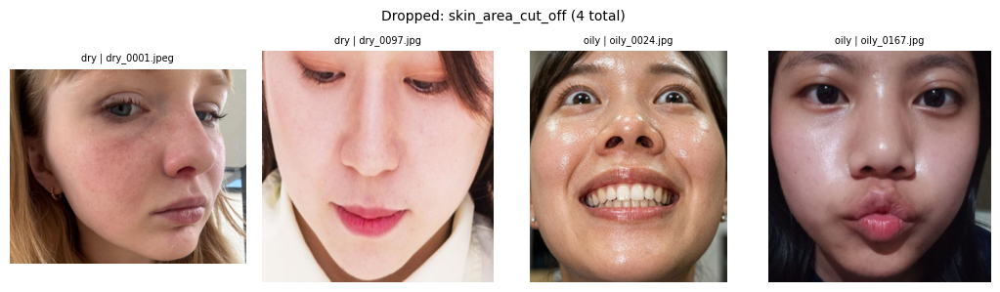

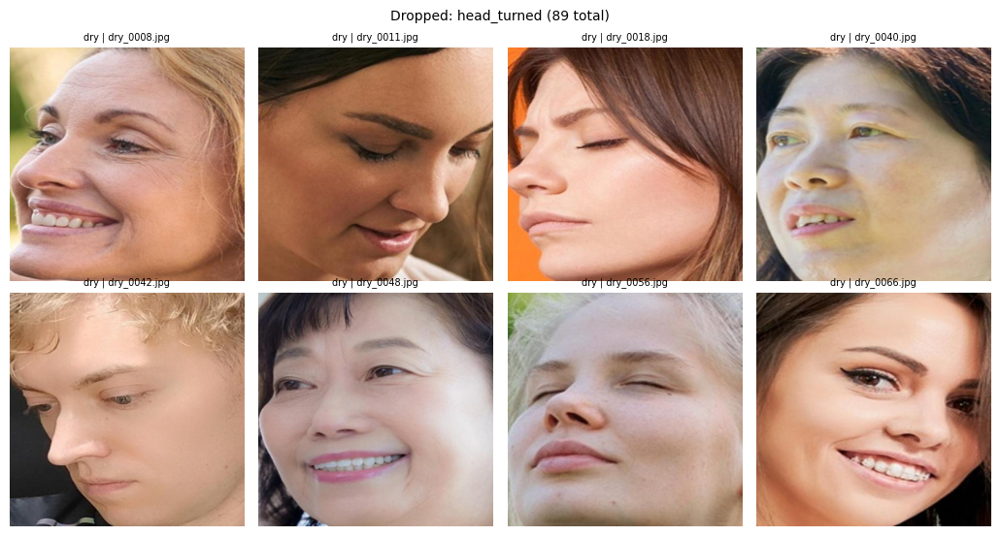

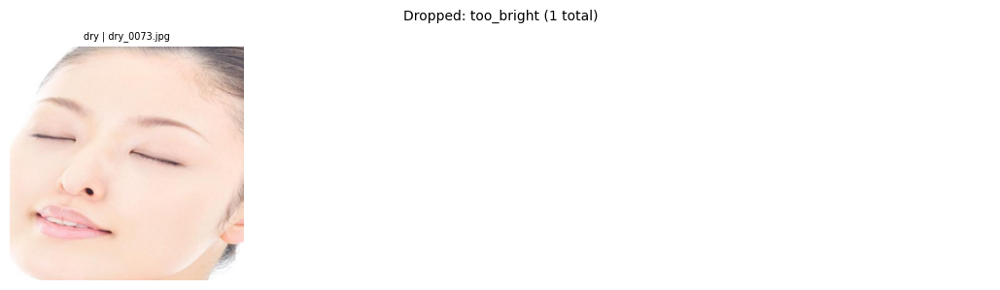

Quality of the images that passed, by class (a preview of Stage 4):


,face_w_px,blur,brightness,yaw_deg
label,,,,
dry,615.7,179.2,148.5,10.1
normal,621.3,184.0,149.7,11.5
oily,455.9,319.0,121.3,6.6


In [7]:
import json

cfg_path = WORK_DIR / "stage2_config.json"
cfg_path.write_text(json.dumps({"work_dir": str(WORK_DIR), "detect_max_side": DETECT_MAX_SIDE,
                                "key_landmarks": list(KEY_LANDMARKS.values())}))
!MPLBACKEND=Agg {SIDE_PY} /kaggle/working/stage2_worker.py {cfg_path}

stage2_cols = ["face_count", "face_x0", "face_y0", "face_x1", "face_y1", "face_w_px", "face_h_px",
               "face_area_frac", "edge_overshoot", "skin_cut_off", "yaw_deg", "blur", "brightness"]
df = df.drop(columns=[c for c in stage2_cols if c in df.columns])
metrics = pd.read_csv(WORK_DIR / "stage2_metrics.csv")
df = df.merge(metrics, on="img_id", how="left")

drop(df["face_count"].eq(-1), "unreadable")
drop(df["face_count"].eq(0), "no_face")
drop(df["face_count"].gt(1), "multiple_faces")
drop(df["skin_cut_off"].eq(True), "skin_area_cut_off")
drop(df["face_w_px"].lt(MIN_FACE_WIDTH_PX), "face_too_small")
drop(df["yaw_deg"].gt(MAX_YAW_DEG), "head_turned")
drop(df["blur"].lt(MIN_BLUR_SCORE), "blurry")
drop(df["brightness"].lt(MIN_BRIGHTNESS), "too_dark")
drop(df["brightness"].gt(MAX_BRIGHTNESS), "too_bright")

kept_ids = set(df.loc[df["status"] == "keep", "img_id"])
with np.load(WORK_DIR / "landmarks_all.npz") as all_lm:
    np.savez_compressed(WORK_DIR / "landmarks.npz", **{k: all_lm[k] for k in all_lm.files if k in kept_ids})
df.to_csv(WORK_DIR / "manifest_stage2.csv", index=False)
funnel("Stage 2")

for reason in ["no_face", "multiple_faces", "skin_area_cut_off", "face_too_small",
               "head_turned", "blurry", "too_dark", "too_bright"]:
    sample = df[df["drop_reason"] == reason].head(8)
    if len(sample):
        show_images(list(sample.index),
                    [f"{r.label} | {Path(r.path).name[:24]}" for r in sample.itertuples()],
                    suptitle=f"Dropped: {reason} ({(df['drop_reason'] == reason).sum()} total)")

print("Quality of the images that passed, by class (a preview of Stage 4):")
display(df[df["status"] == "keep"].groupby("label")[["face_w_px", "blur", "brightness", "yaw_deg"]]
          .median().round(1))

In [8]:
print(df["status"].value_counts().to_string())
display(df[df["status"] == "keep"].groupby(["label", "source"]).size().unstack(fill_value=0))

status
keep    589
drop    125


source,web
label,
dry,121
normal,189
oily,279


## Stage 3

In [9]:
%%writefile /kaggle/working/skin_preprocess.py
"""Shared skin-type preprocessing: used by BOTH the training notebook and the backend.

preprocess(img, landmarks) -> 224x224 RGB image containing only skin:
  1. rotate so the eyes are level,
  2. crop around the face and scale width and height separately, so every face fills the
     square the same way (removes stretched sources and face-shape differences),
  3. paint everything that is not skin (outside the face outline, eyes and eyebrows,
     lips and mouth, the top of the forehead where hair/hats usually are) with the
     ImageNet mean colour, so it becomes ~0 after normalization,
  4. if a sharpness target is set, blur sharper faces down to that target, so the model
     cannot tell sources apart by how sharp the photo is.

Inputs:
  img        PIL.Image, already EXIF-transposed, any size
  landmarks  array (468, >=2) of MediaPipe FaceMesh landmarks, normalized x,y in [0,1]
             (relative to img; normalized coords do not depend on the image being resized)

Only numpy and Pillow are needed, so it runs on Kaggle (Python 3.13) and in the backend (3.11).
"""
from __future__ import annotations

import math

import numpy as np
from PIL import Image, ImageDraw, ImageFilter

VERSION = "skin-preprocess-2"
OUT_SIZE = 224
MARGIN = 0.05                  # extra space around the face box, per side, as a fraction of its size
FILL = (124, 116, 104)         # ImageNet mean RGB -> ~0 after normalization
EXCLUDE_GROW_PX = 9            # how far the eye/brow/lip masks are grown (odd number, in output pixels)
OVAL_SHRINK_PX = 5             # shrink the face outline slightly to drop hairline/background edge pixels
FOREHEAD_KEEP = 0.6            # keep this fraction of the forehead (brows -> top of outline); the top part is
                               # often hair, a fringe or a hat
NORMALIZE_ASPECT = True        # scale x and y separately so the face outline fills the square
SHARPNESS_TARGET = None        # set from the training data (see preprocess_config.json); None = no blurring
SHARPNESS_CORE_PX = 7          # skin mask is shrunk by this before measuring sharpness (avoids mask edges)

# MediaPipe FaceMesh landmark indices
FACE_OVAL = [10, 338, 297, 332, 284, 251, 389, 356, 454, 323, 361, 288, 397, 365, 379, 378, 400, 377,
             152, 148, 176, 149, 150, 136, 172, 58, 132, 93, 234, 127, 162, 21, 54, 103, 67, 109]
LIPS_OUTER = [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 409, 270, 269, 267, 0, 37, 39, 40, 185]
EYE_A = [33, 7, 163, 144, 145, 153, 154, 155, 133, 173, 157, 158, 159, 160, 161, 246]
EYE_B = [362, 382, 381, 380, 374, 373, 390, 249, 263, 466, 388, 387, 386, 385, 384, 398]
BROW_A = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46]
BROW_B = [300, 293, 334, 296, 336, 285, 295, 282, 283, 276]
EYE_A_CORNERS = [33, 133]
EYE_B_CORNERS = [362, 263]


def _convex_hull(points: np.ndarray) -> list[tuple[float, float]]:
    """Monotone-chain convex hull of 2D points."""
    pts = sorted(map(tuple, points.tolist()))
    if len(pts) <= 2:
        return pts

    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

    lower, upper = [], []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]


def align_crop(img: Image.Image, landmarks: np.ndarray, size: int = OUT_SIZE):
    """Rotate (eyes level), crop a square around the face, resize to `size`.

    Returns (aligned RGB image, landmarks in output pixel coordinates (468, 2), roll angle in degrees,
    boolean array of output pixels that come from inside the original photo).
    """
    img = img.convert("RGB")
    W, H = img.size
    p = landmarks[:, :2].astype(np.float64) * [W, H]               # landmark pixels in the input image

    eye_a = p[EYE_A_CORNERS].mean(axis=0)
    eye_b = p[EYE_B_CORNERS].mean(axis=0)
    left, right = (eye_a, eye_b) if eye_a[0] <= eye_b[0] else (eye_b, eye_a)
    theta = math.atan2(right[1] - left[1], right[0] - left[0])     # roll of the eye line
    c, s = math.cos(theta), math.sin(theta)
    rot = np.array([[c, s], [-s, c]])                                # rotates by -theta (levels the eyes)

    q = p @ rot.T                                                    # all landmarks, rotated frame
    oval = q[FACE_OVAL]
    lo, hi = oval.min(axis=0), oval.max(axis=0)
    center = (lo + hi) / 2
    extent = (hi - lo) * (1 + 2 * MARGIN)
    sides = extent if NORMALIZE_ASPECT else np.array([extent.max(), extent.max()])

    # Downscale very large inputs first so the affine resample is not aliased.
    if sides.max() > 2 * size:
        f = (2 * size) / sides.max()
        img = img.resize((max(1, round(W * f)), max(1, round(H * f))), Image.LANCZOS)
        p, q, center, sides = p * f, q * f, center * f, sides * f

    kx, ky = sides / size                                            # input pixels per output pixel (x, y)
    inv = rot.T                                                      # rotates by +theta
    corner = center - sides / 2
    origin = inv @ corner                                            # input point mapped to output (0, 0)
    coeffs = (kx * inv[0, 0], ky * inv[0, 1], origin[0], kx * inv[1, 0], ky * inv[1, 1], origin[1])
    out = img.transform((size, size), Image.AFFINE, coeffs, resample=Image.BICUBIC, fillcolor=FILL)
    inside = np.asarray(Image.new("L", img.size, 255).transform((size, size), Image.AFFINE, coeffs,
                                                                resample=Image.NEAREST, fillcolor=0)) > 0
    lm_out = (q - corner) / np.array([kx, ky])
    return out, lm_out, math.degrees(theta), inside


def skin_mask(lm_out: np.ndarray, size: int = OUT_SIZE, inside: np.ndarray | None = None) -> np.ndarray:
    """Boolean mask (size, size): True where the pixel is skin we want the model to see.

    `inside` (from align_crop) removes pixels that were outside the original photo.
    """
    keep = Image.new("L", (size, size), 0)
    ImageDraw.Draw(keep).polygon([tuple(xy) for xy in lm_out[FACE_OVAL]], fill=255)
    if OVAL_SHRINK_PX > 1:
        keep = keep.filter(ImageFilter.MinFilter(OVAL_SHRINK_PX))

    excl = Image.new("L", (size, size), 0)
    draw = ImageDraw.Draw(excl)
    for idx in (EYE_A + BROW_A, EYE_B + BROW_B, LIPS_OUTER):
        draw.polygon(_convex_hull(lm_out[idx]), fill=255)
    if EXCLUDE_GROW_PX > 1:
        excl = excl.filter(ImageFilter.MaxFilter(EXCLUDE_GROW_PX))

    mask = (np.asarray(keep) > 127) & ~(np.asarray(excl) > 127)

    # Cap the forehead: keep only FOREHEAD_KEEP of the distance from the brows up to the outline top.
    brow_top = lm_out[BROW_A + BROW_B, 1].min()
    oval_top = lm_out[FACE_OVAL, 1].min()
    cut = int(round(brow_top - FOREHEAD_KEEP * (brow_top - oval_top)))
    if cut > 0:
        mask[:min(cut, size)] = False
    if inside is not None:
        mask &= inside
    return mask


def skin_sharpness(img: Image.Image, mask: np.ndarray) -> float:
    """Variance of the Laplacian over the inner skin area (higher = sharper)."""
    core = np.asarray(Image.fromarray(mask.astype(np.uint8) * 255).filter(ImageFilter.MinFilter(SHARPNESS_CORE_PX))) > 127
    g = np.asarray(img.convert("L"), np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    core = core[1:-1, 1:-1]
    return float(lap[core].var()) if core.sum() > 50 else float("nan")


def match_sharpness(img: Image.Image, mask: np.ndarray, target: float, iters: int = 12):
    """Gaussian-blur `img` just enough that its skin sharpness drops to `target`. Never sharpens."""
    s0 = skin_sharpness(img, mask)
    if not (s0 > target):
        return img, s0, 0.0
    lo, hi = 0.0, 6.0
    best = img.filter(ImageFilter.GaussianBlur(hi))
    for _ in range(iters):
        mid = (lo + hi) / 2
        cand = img.filter(ImageFilter.GaussianBlur(mid))
        if skin_sharpness(cand, mask) > target:
            lo = mid
        else:
            hi, best = mid, cand
    return best, s0, hi


def preprocess(img: Image.Image, landmarks: np.ndarray, size: int = OUT_SIZE, return_details: bool = False,
               sharpness_target: float | None = "default"):
    """Align, crop, mask and (optionally) match sharpness. Returns the 224x224 RGB model input."""
    if sharpness_target == "default":
        sharpness_target = SHARPNESS_TARGET
    aligned, lm_out, roll, inside = align_crop(img, landmarks, size)
    mask = skin_mask(lm_out, size, inside)
    if sharpness_target is not None:
        aligned, sharp_before, blur_radius = match_sharpness(aligned, mask, sharpness_target)
    else:
        sharp_before, blur_radius = skin_sharpness(aligned, mask), 0.0
    arr = np.asarray(aligned).copy()
    arr[~mask] = FILL
    masked = Image.fromarray(arr)
    if return_details:
        return masked, {"aligned": aligned, "mask": mask, "landmarks": lm_out, "roll_deg": roll,
                        "skin_fraction": float(mask.mean()), "sharpness_before": sharp_before,
                        "sharpness_after": skin_sharpness(aligned, mask), "blur_radius": blur_radius}
    return masked

Writing /kaggle/working/skin_preprocess.py


Stage 3a align/crop/mask:   0%|          | 0/589 [00:00<?, ?it/s]

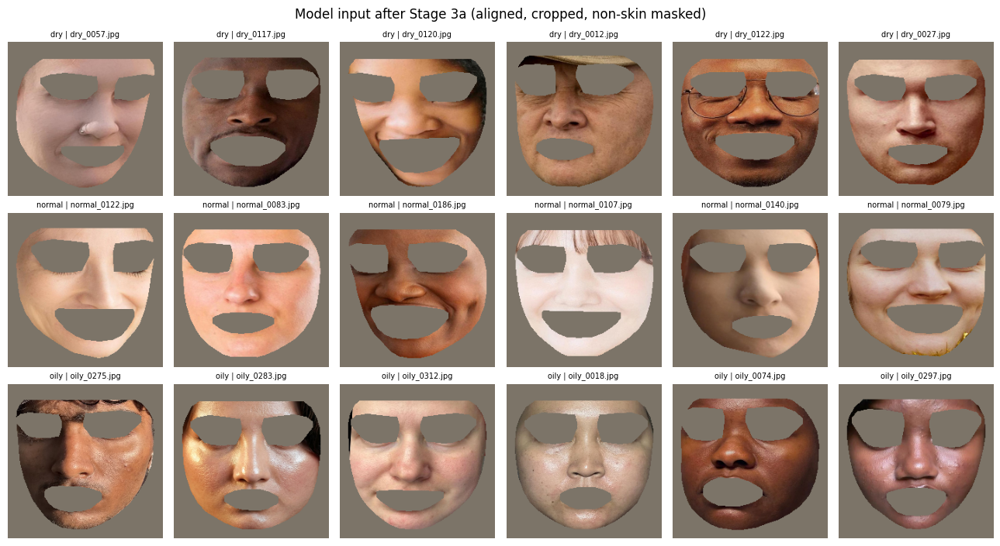

=== after Stage 3a ===


,total,kept
label,,
dry,151,121
normal,217,189
oily,346,279
ALL,714,589


label,dry,normal,oily
drop_reason,,,
duplicate,2,3,21
head_turned,23,23,43
label_conflict,1,2,1
skin_area_cut_off,2,0,2
too_bright,1,0,0
unreadable,1,0,0


Median roll corrected: 3.7 deg | median skin fraction: 0.46


In [10]:
import sys
sys.path.insert(0, "/kaggle/working")
import importlib
import skin_preprocess as sp
importlib.reload(sp)

CROP_DIR = WORK_DIR / "crops"
CROP_DIR.mkdir(exist_ok=True)
MIN_SKIN_FRACTION = 0.20   # drop if less than 20% of the 224x224 crop is usable skin

df = pd.read_csv(WORK_DIR / "manifest_stage2.csv")   # so this cell also works after a kernel restart
landmarks = np.load(WORK_DIR / "landmarks.npz")

info = {}
for i in tqdm(df.index[df["status"] == "keep"], desc="Stage 3a align/crop/mask"):
    img_id = df.at[i, "img_id"]
    masked, det = sp.preprocess(load_rgb(df.at[i, "path"]), landmarks[img_id].astype(np.float32),
                                return_details=True)
    masked.save(CROP_DIR / f"{img_id}.png")
    info[i] = {"roll_deg": det["roll_deg"], "skin_fraction": det["skin_fraction"],
               "crop_path": str(CROP_DIR / f"{img_id}.png")}

df = df.join(pd.DataFrame.from_dict(info, orient="index"))
drop(df["skin_fraction"].lt(MIN_SKIN_FRACTION), "too_little_skin")
kept = df[df["status"] == "keep"]

# What the model will see: 6 random crops per class
sample = pd.concat([g.sample(min(6, len(g)), random_state=0) for _, g in kept.groupby("label")])
fig, axes = plt.subplots(sample["label"].nunique(), 6, figsize=(13, 2.4 * sample["label"].nunique()))
for ax in np.ravel(axes):
    ax.axis("off")
for r, (label, g) in enumerate(sample.groupby("label")):
    for c, row in enumerate(g.itertuples()):
        ax = np.atleast_2d(axes)[r, c]
        ax.imshow(Image.open(row.crop_path))
        ax.set_title(f"{label} | {Path(row.path).name[:18]}", fontsize=7)
plt.suptitle("Model input after Stage 3a (aligned, cropped, non-skin masked)")
plt.tight_layout()
plt.show()

df.to_csv(WORK_DIR / "manifest_stage3a.csv", index=False)
funnel("Stage 3a")
print(f"Median roll corrected: {kept['roll_deg'].abs().median():.1f} deg | "
      f"median skin fraction: {kept['skin_fraction'].median():.2f}")

Stage 3b signatures:   0%|          | 0/589 [00:00<?, ?it/s]

589 images, 173166 pairs; 27301 pairs with shading_r >= 0.6 or texture_r >= 0.2 saved

Pair counts by shading_r band:


cross_class,cross class,same class
shading_r,,
"[0.6, 0.72)",4011,3136
"[0.72, 0.8)",847,612
"[0.8, 0.85)",140,120
"[0.85, 0.9)",33,17
"[0.9, 0.95)",0,3
"[0.95, 1.01)",0,2


Pair counts by texture_r band:


cross_class,cross class,same class
texture_r,,
"[0.2, 0.3)",9948,6047
"[0.3, 0.4)",2600,1895
"[0.4, 0.5)",690,563
"[0.5, 0.6)",153,123
"[0.6, 0.8)",29,18
"[0.8, 1.01)",0,2


Pairs with shading_r >= 0.85, by texture_r band (this is what Stage 3 called duplicates):


cross_class,False,True
texture_r,,
"[0.2, 0.3)",3,9
"[0.3, 0.4)",5,5
"[0.4, 0.5)",8,12
"[0.5, 0.6)",3,1
"[0.6, 0.8)",1,2
"[0.8, 1.01)",2,0


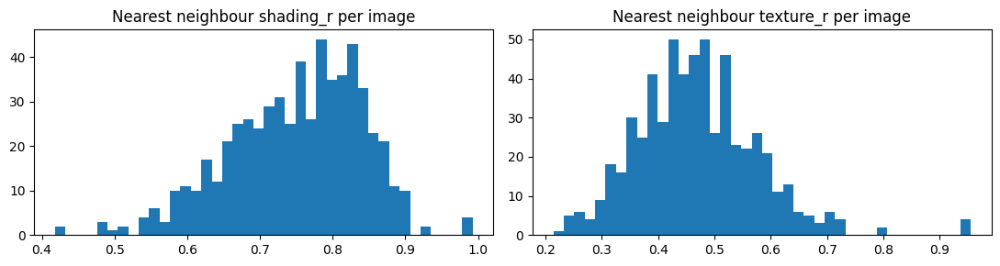

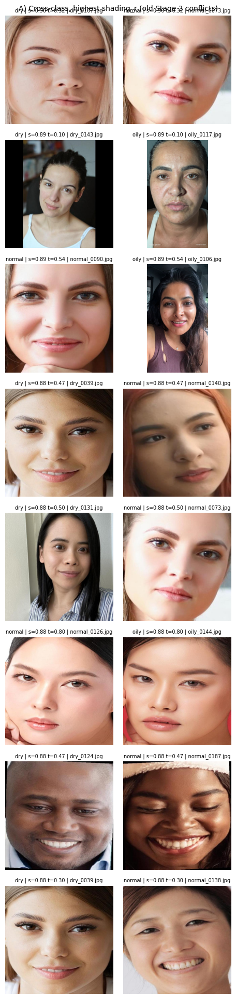

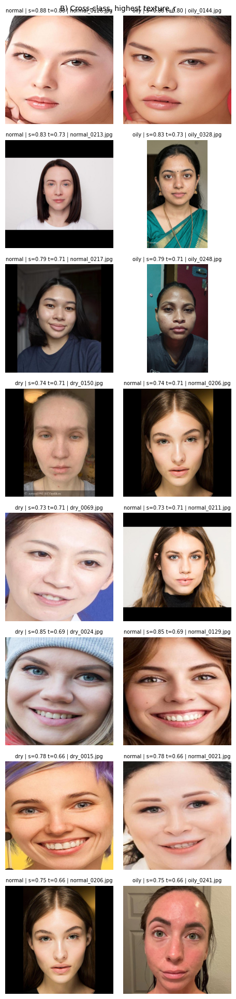

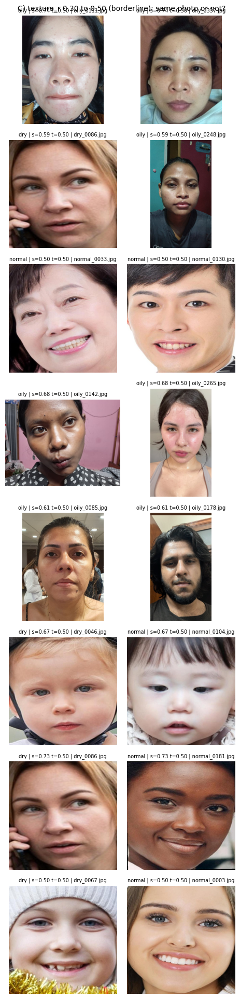

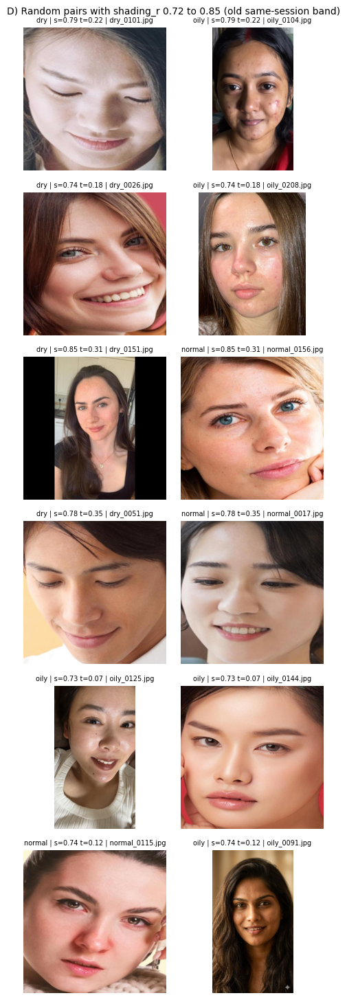

In [11]:
# Stage 3b diagnostics: how similar is every pair of aligned faces?
# shading_r: correlation of the broad light/shadow pattern (48x48)   -> high for copies, but also for
#            different people photographed the same way
# texture_r: correlation of fine skin detail (pores, freckles, moles; 112x112) -> high only when it is
#            the same skin in the same photo
# Both are also checked against the mirrored face. Nothing is dropped in this cell.
from PIL import ImageFilter

FILL_RGB = np.array(sp.FILL)
LF_N, HF_N = 48, 112


def signatures(crop_path):
    a = np.asarray(Image.open(crop_path).convert("RGB"))
    mask_img = Image.fromarray(np.any(a != FILL_RGB, axis=2).astype(np.uint8) * 255)
    gray = Image.fromarray(a).convert("L")
    lf = np.asarray(gray.resize((LF_N, LF_N), Image.BOX), np.float32).ravel()
    lf_m = (np.asarray(mask_img.resize((LF_N, LF_N), Image.BOX)) > 200).ravel()
    g = gray.resize((HF_N, HF_N), Image.BOX)
    hf = (np.asarray(g.filter(ImageFilter.GaussianBlur(0.7)), np.float32)
          - np.asarray(g.filter(ImageFilter.GaussianBlur(3)), np.float32)).ravel()
    hf_m = (np.asarray(mask_img.resize((HF_N, HF_N), Image.BOX).filter(ImageFilter.MinFilter(5))) > 200).ravel()
    out = []
    for v, m in ((lf, lf_m), (hf, hf_m)):
        z = np.zeros_like(v)
        if m.sum() > 10:
            z[m] = (v[m] - v[m].mean()) / (v[m].std() + 1e-6)
        out.append((z, m.astype(np.float32)))
    return out


def corr_matrix(Z, M, n):
    def flip(A):
        return A.reshape(len(A), n, n)[:, :, ::-1].reshape(len(A), -1)
    C = None
    for Zb, Mb in ((Z, M), (flip(Z), flip(M))):
        c = (Z @ Zb.T) / (np.sqrt((Z ** 2 @ Mb.T) * (M @ (Zb ** 2).T)) + 1e-6)
        C = c if C is None else np.maximum(C, c)
    np.fill_diagonal(C, -1)
    return C


kept = df[df["status"] == "keep"]
ids = kept.index.to_numpy()
sigs = [signatures(p) for p in tqdm(kept["crop_path"], desc="Stage 3b signatures")]
C_lf = corr_matrix(np.stack([s[0][0] for s in sigs]), np.stack([s[0][1] for s in sigs]), LF_N)
C_hf = corr_matrix(np.stack([s[1][0] for s in sigs]), np.stack([s[1][1] for s in sigs]), HF_N)

iu = np.triu_indices(len(ids), 1)
pairs = pd.DataFrame({"a": ids[iu[0]], "b": ids[iu[1]],
                      "shading_r": C_lf[iu].round(3), "texture_r": C_hf[iu].round(3)})
lab = df["label"]
pairs["cross_class"] = lab.loc[pairs["a"]].to_numpy() != lab.loc[pairs["b"]].to_numpy()
pairs = pairs[(pairs["shading_r"] >= 0.6) | (pairs["texture_r"] >= 0.2)].reset_index(drop=True)
pairs.to_csv(WORK_DIR / "pair_similarity.csv", index=False)
print(f"{len(ids)} images, {len(iu[0])} pairs; {len(pairs)} pairs with shading_r >= 0.6 or texture_r >= 0.2 saved")

bands_s = pd.cut(pairs["shading_r"], [0.6, 0.72, 0.8, 0.85, 0.9, 0.95, 1.01], right=False)
bands_t = pd.cut(pairs["texture_r"], [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.01], right=False)
print("\nPair counts by shading_r band:")
display(pd.crosstab(bands_s, pairs["cross_class"].map({False: "same class", True: "cross class"})))
print("Pair counts by texture_r band:")
display(pd.crosstab(bands_t, pairs["cross_class"].map({False: "same class", True: "cross class"})))
print("Pairs with shading_r >= 0.85, by texture_r band (this is what Stage 3 called duplicates):")
display(pd.crosstab(bands_t[pairs["shading_r"] >= 0.85], pairs.loc[pairs["shading_r"] >= 0.85, "cross_class"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(C_lf.max(axis=1), bins=40); axes[0].set_title("Nearest neighbour shading_r per image")
axes[1].hist(C_hf.max(axis=1), bins=40); axes[1].set_title("Nearest neighbour texture_r per image")
plt.tight_layout()
plt.show()


def sim_gallery(sub, title, n=8):
    sub = sub.head(n)
    ids_ = [x for r in sub.itertuples() for x in (r.a, r.b)]
    titles = [f"{df.at[x, 'label']} | s={r.shading_r:.2f} t={r.texture_r:.2f} | {Path(df.at[x, 'path']).name[:16]}"
              for r in sub.itertuples() for x in (r.a, r.b)]
    show_images(ids_, titles, ncols=2, size=2.4, suptitle=title)


cross = pairs[pairs["cross_class"]]
sim_gallery(cross.sort_values("shading_r", ascending=False), "A) Cross-class, highest shading_r (old Stage 3 conflicts)")
sim_gallery(cross.sort_values("texture_r", ascending=False), "B) Cross-class, highest texture_r")
mid_t = pairs[(pairs["texture_r"] >= 0.3) & (pairs["texture_r"] < 0.5)].sort_values("texture_r", ascending=False)
sim_gallery(mid_t, "C) texture_r 0.30 to 0.50 (borderline): same photo or not?")
band_s = pairs[(pairs["shading_r"] >= 0.72) & (pairs["shading_r"] < 0.85)].sample(frac=1, random_state=0)
sim_gallery(band_s, "D) Random pairs with shading_r 0.72 to 0.85 (old same-session band)", n=6)

2 duplicate pairs -> 2 dropped as duplicates, 0 dropped as cross-class conflicts
587 images in 586 split groups (1 groups with more than one image)


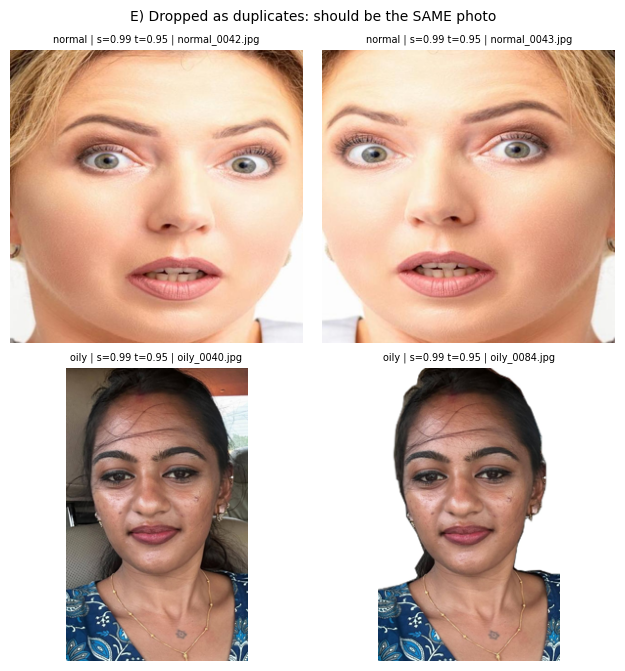

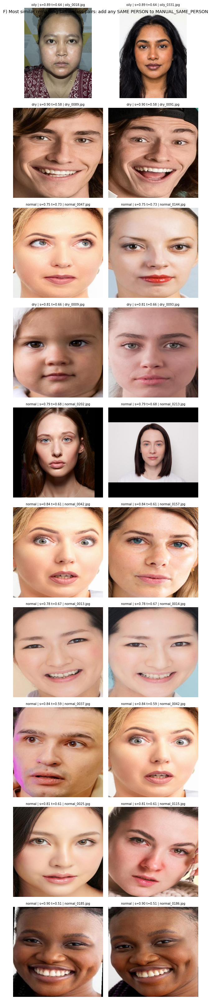

=== after Stage 3 ===


,total,kept
label,,
dry,151,121
normal,217,188
oily,346,278
ALL,714,587


label,dry,normal,oily
drop_reason,,,
duplicate,2,3,21
duplicate_aligned,0,1,1
head_turned,23,23,43
label_conflict,1,2,1
skin_area_cut_off,2,0,2
too_bright,1,0,0
unreadable,1,0,0


In [12]:
# Stage 3b: apply the duplicate rule chosen from the diagnostics, and set split groups.
# Rule (from your galleries): only BOTH signals high means the same photo.
DUP_TEXTURE = 0.80
DUP_SHADING = 0.85
# Same person, different photo: no automatic signal is reliable on this data, so list confirmed pairs
# by file name. Every file in one entry ends up in the same split. Add pairs from gallery F below.
MANUAL_SAME_PERSON = [
    ["dry_0099.jpg", "dry_0100.jpg"],
]

df = pd.read_csv(WORK_DIR / "manifest_stage3a.csv")
pairs = pd.read_csv(WORK_DIR / "pair_similarity.csv")
alive = set(df.index[df["status"] == "keep"])
pairs = pairs[pairs["a"].isin(alive) & pairs["b"].isin(alive)]

parent = {i: i for i in df.index}
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# 1) duplicates
dups = pairs[(pairs["texture_r"] >= DUP_TEXTURE) & (pairs["shading_r"] >= DUP_SHADING)]
for r in dups.itertuples():
    union(r.a, r.b)
n_dup = n_conf = 0
groups = pd.Series({i: find(i) for i in alive})
for _, members in groups.groupby(groups):
    members = list(members.index)
    if len(members) < 2:
        continue
    if df.loc[members, "label"].nunique() > 1:
        df.loc[members, ["status", "drop_reason"]] = ["drop", "label_conflict_aligned"]
        n_conf += len(members)
    else:
        best = (df.loc[members, "width"] * df.loc[members, "height"]).idxmax()
        rest = [m for m in members if m != best]
        df.loc[rest, ["status", "drop_reason"]] = ["drop", "duplicate_aligned"]
        n_dup += len(rest)
print(f"{len(dups)} duplicate pairs -> {n_dup} dropped as duplicates, {n_conf} dropped as cross-class conflicts")

# 2) split groups: one group per image, merged for confirmed same-person pairs
parent = {i: i for i in df.index}
name_to_idx = {Path(p).name: i for i, p in df["path"].items()}
for entry in MANUAL_SAME_PERSON:
    found = [name_to_idx[n] for n in entry if n in name_to_idx]
    missing = [n for n in entry if n not in name_to_idx]
    if missing:
        print(f"WARNING: not found, check the file names: {missing}")
    for j in found[1:]:
        union(found[0], j)
df["split_group"] = [f"sg_{df.at[find(i), 'img_id']}" for i in df.index]
kept = df[df["status"] == "keep"]
labels_per_group = kept.groupby("split_group")["label"].nunique()
if (labels_per_group > 1).any():
    print("NOTE: these same-person groups span more than one class (check the labels):",
          list(labels_per_group[labels_per_group > 1].index))
print(f"{len(kept)} images in {kept['split_group'].nunique()} split groups "
      f"({(kept['split_group'].value_counts() > 1).sum()} groups with more than one image)")


def sim_gallery(sub, title, n=8):
    sub = sub.head(n)
    ids_ = [x for r in sub.itertuples() for x in (r.a, r.b)]
    titles = [f"{df.at[x, 'label']} | s={r.shading_r:.2f} t={r.texture_r:.2f} | {Path(df.at[x, 'path']).name[:16]}"
              for r in sub.itertuples() for x in (r.a, r.b)]
    show_images(ids_, titles, ncols=2, size=3.2, suptitle=title)


sim_gallery(
    dups.sort_values("texture_r", ascending=False),
    "E) Dropped as duplicates: should be the SAME photo",
    n=8
)

still = set(df.index[df["status"] == "keep"])
review = pairs[
    pairs["a"].isin(still)
    & pairs["b"].isin(still)
    & ~pairs["cross_class"]
]
review = review.assign(
    score=review["shading_r"] + review["texture_r"]
).sort_values("score", ascending=False)

sim_gallery(
    review,
    "F) Most similar remaining same-class pairs: add any SAME PERSON to MANUAL_SAME_PERSON",
    n=10
)

df.to_csv(WORK_DIR / "manifest_stage3.csv", index=False)
funnel("Stage 3")

## Stage 4

Stage 4 measuring:   0%|          | 0/587 [00:00<?, ?it/s]

587 images measured

Medians by class:


label,dry,normal,oily
ita,47.84,46.71,28.69
skin_L,69.35,72.22,60.67
skin_chroma,20.93,23.16,22.88
skin_redness_a,13.09,13.78,14.14
crop_sharpness,120.84,119.26,389.15
face_w_px,615.71,621.27,455.39
aspect_hw,1.00,1.00,1.34
is_square,1.00,1.00,0.00
letterbox,0.00,0.00,0.00
bits_per_px,0.72,0.69,0.94


Skin-tone groups by class (% of the class):


label,dry,normal,oily
tone,,,
dark,5.8,6.4,10.5
brown,10.8,16.0,18.8
tan,9.2,5.9,19.1
intermediate,11.7,10.6,28.5
light,31.7,28.7,18.1
very light,30.8,32.4,5.1


label,dry,normal,oily,All
tone,,,,
dark,7,12,29,48
brown,13,30,52,95
tan,11,11,53,75
intermediate,14,20,79,113
light,38,54,50,142
very light,37,61,14,112
All,120,188,277,585


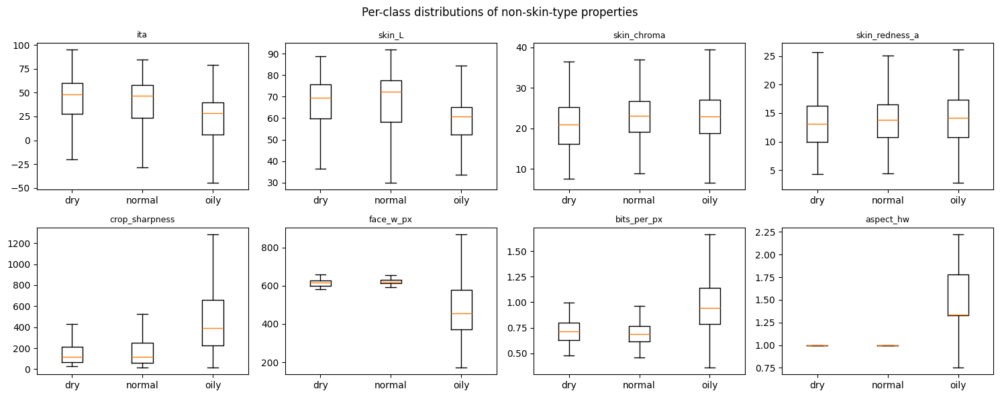

Shortcut probe: balanced accuracy with 5-fold grouped CV (chance = 0.333). Higher = that property alone gives the class away.


,logistic,boosted trees,best_minus_chance
features,,,
visible in crop (all),0.565,0.607,0.274
file format (all),0.617,0.621,0.288
ita,0.399,0.460,0.127
skin_L,0.431,0.459,0.126
skin_chroma,0.368,0.311,0.035
skin_redness_a,0.362,0.327,0.029
crop_sharpness,0.483,0.476,0.150
face_w_px,0.549,0.631,0.298
abs_roll,0.380,0.329,0.047


Saved manifest_stage4.csv


In [13]:
# Stage 4: measure non-skin-type differences between classes, then test whether they predict the class.
# Nothing is dropped or changed here; the corrections are decided from these results.
from PIL import ImageFilter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(WORK_DIR / "manifest_stage3.csv")
FILL_RGB = np.array(sp.FILL)


def srgb_to_lab(rgb):
    # rgb: (N, 3) in 0..255 -> (N, 3) CIE L*a*b* (D65)
    c = rgb / 255.0
    c = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    xyz = c @ np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]).T
    xyz /= np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.stack([116 * f[:, 1] - 16, 500 * (f[:, 0] - f[:, 1]), 200 * (f[:, 1] - f[:, 2])], axis=1)


def letterbox_fraction(img):
    # share of the image taken by near-black bars at the edges (phone screenshots, padded photos)
    g = np.asarray(img.convert("L").resize((128, 128)), np.float32)
    dark_rows = (g.mean(axis=1) < 12) & (g.std(axis=1) < 6)
    dark_cols = (g.mean(axis=0) < 12) & (g.std(axis=0) < 6)
    def edge_run(v):
        n = 0
        for x in v:
            if not x:
                break
            n += 1
        return n
    return (edge_run(dark_rows) + edge_run(dark_rows[::-1]) + edge_run(dark_cols) + edge_run(dark_cols[::-1])) / 128


def crop_features(crop_path):
    a = np.asarray(Image.open(crop_path).convert("RGB"))
    skin = np.any(a != FILL_RGB, axis=2)
    core = np.asarray(Image.fromarray(skin.astype(np.uint8) * 255).filter(ImageFilter.MinFilter(7))) > 127
    lab = srgb_to_lab(a[skin].astype(np.float64))
    L, A, B = lab[:, 0], lab[:, 1], lab[:, 2]
    g = np.asarray(Image.fromarray(a).convert("L"), np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    ita = np.degrees(np.arctan2(L - 50, B))
    return {"ita": float(np.median(ita)), "skin_L": float(np.median(L)),
            "skin_chroma": float(np.median(np.hypot(A, B))), "skin_redness_a": float(np.median(A)),
            "crop_sharpness": float(lap[core[1:-1, 1:-1]].var())}


feats = {}
for i in tqdm(df.index[df["status"] == "keep"], desc="Stage 4 measuring"):
    f = crop_features(df.at[i, "crop_path"])
    img = load_rgb(df.at[i, "path"])
    f["letterbox"] = letterbox_fraction(img)
    feats[i] = f
df = df.drop(columns=[c for c in ["ita", "skin_L", "skin_chroma", "skin_redness_a", "crop_sharpness", "letterbox"]
                      if c in df.columns]).join(pd.DataFrame.from_dict(feats, orient="index"))
df["aspect_hw"] = df["height"] / df["width"]
df["is_square"] = (df["width"] == df["height"]).astype(int)
df["bits_per_px"] = df["file_kb"] * 1024 * 8 / (df["width"] * df["height"])
df["abs_roll"] = df["roll_deg"].abs()
# ITA skin-tone groups (Chardon et al.); lighting shifts ITA too, so treat it as approximate
df["tone"] = pd.cut(df["ita"], [-90, -30, 10, 28, 41, 55, 90],
                    labels=["dark", "brown", "tan", "intermediate", "light", "very light"])

kept = df[df["status"] == "keep"].copy()
print(f"{len(kept)} images measured")

print("\nMedians by class:")
show_cols = ["ita", "skin_L", "skin_chroma", "skin_redness_a", "crop_sharpness", "face_w_px",
             "aspect_hw", "is_square", "letterbox", "bits_per_px", "abs_roll", "yaw_deg", "skin_fraction"]
display(kept.groupby("label")[show_cols].median().round(2).T)

print("Skin-tone groups by class (% of the class):")
display((pd.crosstab(kept["tone"], kept["label"], normalize="columns") * 100).round(1))
display(pd.crosstab(kept["tone"], kept["label"], margins=True))

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), ["ita", "skin_L", "skin_chroma", "skin_redness_a",
                                   "crop_sharpness", "face_w_px", "bits_per_px", "aspect_hw"]):
    names = sorted(kept["label"].unique())
    ax.boxplot([kept.loc[kept["label"] == c, col].dropna() for c in names], showfliers=False)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names)
    ax.set_title(col, fontsize=9)
plt.suptitle("Per-class distributions of non-skin-type properties")
plt.tight_layout()
plt.show()

# ---- Shortcut probes: can these properties alone predict the class? ----
VISIBLE = ["ita", "skin_L", "skin_chroma", "skin_redness_a", "crop_sharpness", "face_w_px",
           "abs_roll", "yaw_deg", "skin_fraction"]
FORMAT = ["aspect_hw", "is_square", "letterbox", "bits_per_px", "width", "height"]
y = kept["label"].to_numpy()
groups = kept["split_group"].to_numpy()
n_splits = int(min(5, pd.Series(y).value_counts().min()))
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)


def probe(cols, model):
    X = kept[cols].fillna(kept[cols].median()).to_numpy()
    pred = np.empty(len(y), dtype=object)
    for tr, te in cv.split(X, y, groups):
        model.fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
    return balanced_accuracy_score(y, pred)


def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))


def hgb():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                          class_weight="balanced", random_state=0)


chance = 1 / kept["label"].nunique()
rows = []
for name, cols in [("visible in crop (all)", VISIBLE), ("file format (all)", FORMAT)]:
    rows.append({"features": name, "logistic": probe(cols, lr()), "boosted trees": probe(cols, hgb())})
for col in VISIBLE + FORMAT:
    rows.append({"features": col, "logistic": probe([col], lr()), "boosted trees": probe([col], hgb())})
res = pd.DataFrame(rows).set_index("features").round(3)
res["best_minus_chance"] = (res[["logistic", "boosted trees"]].max(axis=1) - chance).round(3)
print(f"Shortcut probe: balanced accuracy with {n_splits}-fold grouped CV (chance = {chance:.3f}). "
      f"Higher = that property alone gives the class away.")
display(res)

df.to_csv(WORK_DIR / "manifest_stage4.csv", index=False)
print("Saved manifest_stage4.csv")

Stage 4b pass 1 (measure):   0%|          | 0/587 [00:00<?, ?it/s]

Natural crop sharpness by class (percentiles):


,0.1,0.2,0.5,0.8
label,,,,
dry,43.5,59.8,120.8,277.9
normal,36.3,53.2,119.3,313.5
oily,100.2,193.0,389.1,777.7


Sharpness target = 53.2 (the 20th percentile of the blurriest class)


Stage 4b pass 2 (final crops):   0%|          | 0/587 [00:00<?, ?it/s]

Stage 4b re-measure:   0%|          | 0/587 [00:00<?, ?it/s]

... (6 outputs left out)

Shortcut probe on what the model can see (chance = 0.333):


,logistic,boosted trees,best_minus_chance
setting,,,
"before: v1 crops, unweighted",0.508,0.535,0.202
"after: v2 crops, unweighted",0.445,0.487,0.154
after: v2 crops + tone weights,0.380,0.437,0.104


After corrections, one property at a time (weighted):


,logistic,boosted trees,best_minus_chance
feature,,,
ita_v2,0.333,0.347,0.014
skin_L_v2,0.333,0.305,-0.000
skin_chroma_v2,0.333,0.336,0.003
skin_redness_a_v2,0.343,0.333,0.010
crop_sharpness_v2,0.346,0.341,0.013
skin_fraction_v2,0.338,0.370,0.037
abs_roll,0.337,0.327,0.004
yaw_deg,0.320,0.365,0.032


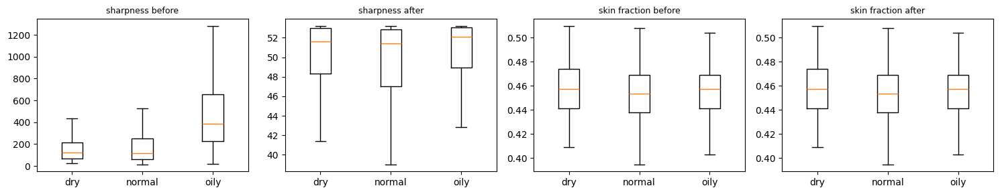

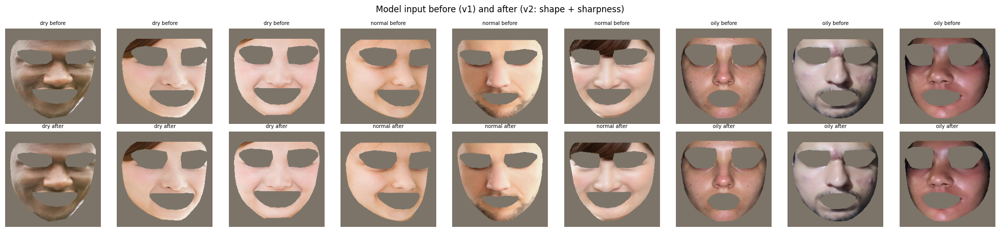

Saved manifest_stage4b.csv and preprocess_config.json: {'preprocess_version': 'skin-preprocess-2', 'normalize_aspect': True, 'sharpness_target': 53.21, 'target_percentile': 20}


In [14]:
#  1) face shape  -> skin_preprocess v2 scales width/height separately (NORMALIZE_ASPECT)
#  2) sharpness   -> blur every crop down to one target taken from the blurriest class
#  3) skin tone   -> sample weights so each tone group has the same class mix
import json
assert "crop_features" in globals(), "Run Cell 13 first"
importlib.reload(sp)
assert sp.VERSION == "skin-preprocess-2", "Re-run Cell 9 (module v2) first"

TARGET_PERCENTILE = 20     # target = this percentile of sharpness in the blurriest class
TONE3_BINS = [-np.inf, 10, 41, np.inf]   # open-ended: real ITA can fall outside +/-90
TONE3_NAMES = ["darker", "medium", "lighter"]
WEIGHT_CLIP = (0.25, 4.0)
CROP_DIR_V2 = WORK_DIR / "crops_v2"
CROP_DIR_V2.mkdir(exist_ok=True)

df = pd.read_csv(WORK_DIR / "manifest_stage4.csv")
landmarks = np.load(WORK_DIR / "landmarks.npz")
keep_idx = df.index[df["status"] == "keep"]

# Pass 1: v2 crops without blurring, to measure natural sharpness per class
raw = {}
for i in tqdm(keep_idx, desc="Stage 4b pass 1 (measure)"):
    _, det = sp.preprocess(load_rgb(df.at[i, "path"]), landmarks[df.at[i, "img_id"]].astype(np.float32),
                           return_details=True, sharpness_target=None)
    raw[i] = {"sharpness_raw_v2": det["sharpness_before"], "skin_fraction_v2": det["skin_fraction"]}
df = df.join(pd.DataFrame.from_dict(raw, orient="index"))
drop(df["skin_fraction_v2"].lt(MIN_SKIN_FRACTION), "too_little_skin")
kept = df[df["status"] == "keep"]

pct = kept.groupby("label")["sharpness_raw_v2"].quantile([0.1, 0.2, 0.5, 0.8]).unstack().round(1)
print("Natural crop sharpness by class (percentiles):")
display(pct)
target = float(kept.groupby("label")["sharpness_raw_v2"].quantile(TARGET_PERCENTILE / 100).min())
print(f"Sharpness target = {target:.1f} (the {TARGET_PERCENTILE}th percentile of the blurriest class)")

# Pass 2: final model inputs, blurred down to the target
fin = {}
for i in tqdm(kept.index, desc="Stage 4b pass 2 (final crops)"):
    masked, det = sp.preprocess(load_rgb(df.at[i, "path"]), landmarks[df.at[i, "img_id"]].astype(np.float32),
                                return_details=True, sharpness_target=target)
    path = CROP_DIR_V2 / f"{df.at[i, 'img_id']}.png"
    masked.save(path)
    fin[i] = {"crop_v2_path": str(path), "blur_radius": det["blur_radius"]}
df = df.join(pd.DataFrame.from_dict(fin, orient="index"))

# Re-measure the visible properties on the final crops
v2 = {i: crop_features(df.at[i, "crop_v2_path"]) for i in tqdm(kept.index, desc="Stage 4b re-measure")}
v2 = pd.DataFrame.from_dict(v2, orient="index").add_suffix("_v2")
df = df.join(v2)
kept = df[df["status"] == "keep"].copy()

# Skin-tone weights: within each tone group, every class gets the same total weight
kept["tone3"] = pd.cut(kept["ita_v2"].fillna(kept["ita_v2"].median()), TONE3_BINS, labels=TONE3_NAMES)
n_missing_ita = kept["ita_v2"].isna().sum()
if n_missing_ita:
    print(f"WARNING: {n_missing_ita} images had no ita_v2 (too little skin after blur); "
          f"assigned the median tone group so they still get a weight")
counts = pd.crosstab(kept["tone3"], kept["label"])
K = kept["label"].nunique()
w = kept.apply(lambda r: counts.loc[r["tone3"]].sum() / (K * counts.loc[r["tone3"], r["label"]]), axis=1)
w = w.clip(*WEIGHT_CLIP)
kept["sample_weight"] = (w / w.mean()).round(4)
print("\nImages per tone group and class:")
display(counts)
print("Sample weight per tone group and class:")
display(kept.pivot_table(index="tone3", columns="label", values="sample_weight", aggfunc="first", observed=False))
print("Weighted class totals (should be about equal):")
display(kept.groupby("label")["sample_weight"].sum().round(1))

# Shortcut probe: before vs after
V1 = ["ita", "skin_L", "skin_chroma", "skin_redness_a", "crop_sharpness", "skin_fraction", "abs_roll", "yaw_deg"]
V2 = ["ita_v2", "skin_L_v2", "skin_chroma_v2", "skin_redness_a_v2", "crop_sharpness_v2", "skin_fraction_v2",
      "abs_roll", "yaw_deg"]
y = kept["label"].to_numpy()
groups = kept["split_group"].to_numpy()
sw = kept["sample_weight"].to_numpy()
n_splits = int(min(5, pd.Series(y).value_counts().min()))
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)


def probe_w(cols, make_model, weighted):
    X = kept[cols].fillna(kept[cols].median()).to_numpy()
    pred = np.empty(len(y), dtype=object)
    for tr, te in cv.split(X, y, groups):
        m = make_model()
        if weighted:
            key = "logisticregression__sample_weight" if hasattr(m, "steps") else "sample_weight"
            m.fit(X[tr], y[tr], **{key: sw[tr]})
        else:
            m.fit(X[tr], y[tr])
        pred[te] = m.predict(X[te])
    return balanced_accuracy_score(y, pred, sample_weight=sw if weighted else None)


chance = 1 / K
rows = []
for name, cols, weighted in [("before: v1 crops, unweighted", V1, False),
                             ("after: v2 crops, unweighted", V2, False),
                             ("after: v2 crops + tone weights", V2, True)]:
    rows.append({"setting": name, "logistic": probe_w(cols, lr, weighted), "boosted trees": probe_w(cols, hgb, weighted)})
summary = pd.DataFrame(rows).set_index("setting").round(3)
summary["best_minus_chance"] = (summary.max(axis=1) - chance).round(3)
print(f"Shortcut probe on what the model can see (chance = {chance:.3f}):")
display(summary)
single = pd.DataFrame([{"feature": c, "logistic": probe_w([c], lr, True), "boosted trees": probe_w([c], hgb, True)}
                       for c in V2]).set_index("feature").round(3)
single["best_minus_chance"] = (single.max(axis=1) - chance).round(3)
print("After corrections, one property at a time (weighted):")
display(single)

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
names = sorted(kept["label"].unique())
for ax, col, title in zip(axes, ["crop_sharpness", "crop_sharpness_v2", "skin_fraction", "skin_fraction_v2"],
                          ["sharpness before", "sharpness after", "skin fraction before", "skin fraction after"]):
    ax.boxplot([kept.loc[kept["label"] == c, col].dropna() for c in names], showfliers=False)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names)
    ax.set_title(title, fontsize=9)
plt.tight_layout()
plt.show()

ex = pd.concat([g.sample(min(3, len(g)), random_state=1) for _, g in kept.groupby("label")])
fig, axes = plt.subplots(2, len(ex), figsize=(2.2 * len(ex), 4.6))
for c, row in enumerate(ex.itertuples()):
    for r, (path, tag) in enumerate([(row.crop_path, "before"), (row.crop_v2_path, "after")]):
        axes[r, c].imshow(Image.open(path))
        axes[r, c].axis("off")
        axes[r, c].set_title(f"{row.label} {tag}", fontsize=7)
plt.suptitle("Model input before (v1) and after (v2: shape + sharpness)")
plt.tight_layout()
plt.show()

df = df.drop(columns=[c for c in ["tone3", "sample_weight"] if c in df.columns]).join(kept[["tone3", "sample_weight"]])
df.to_csv(WORK_DIR / "manifest_stage4b.csv", index=False)
cfg = {"preprocess_version": sp.VERSION, "normalize_aspect": sp.NORMALIZE_ASPECT,
       "sharpness_target": round(target, 2), "target_percentile": TARGET_PERCENTILE}
(WORK_DIR / "preprocess_config.json").write_text(json.dumps(cfg, indent=2))
print("Saved manifest_stage4b.csv and preprocess_config.json:", cfg)

60 photos, numbered 1 to 60. Do not look at the labels or file names.


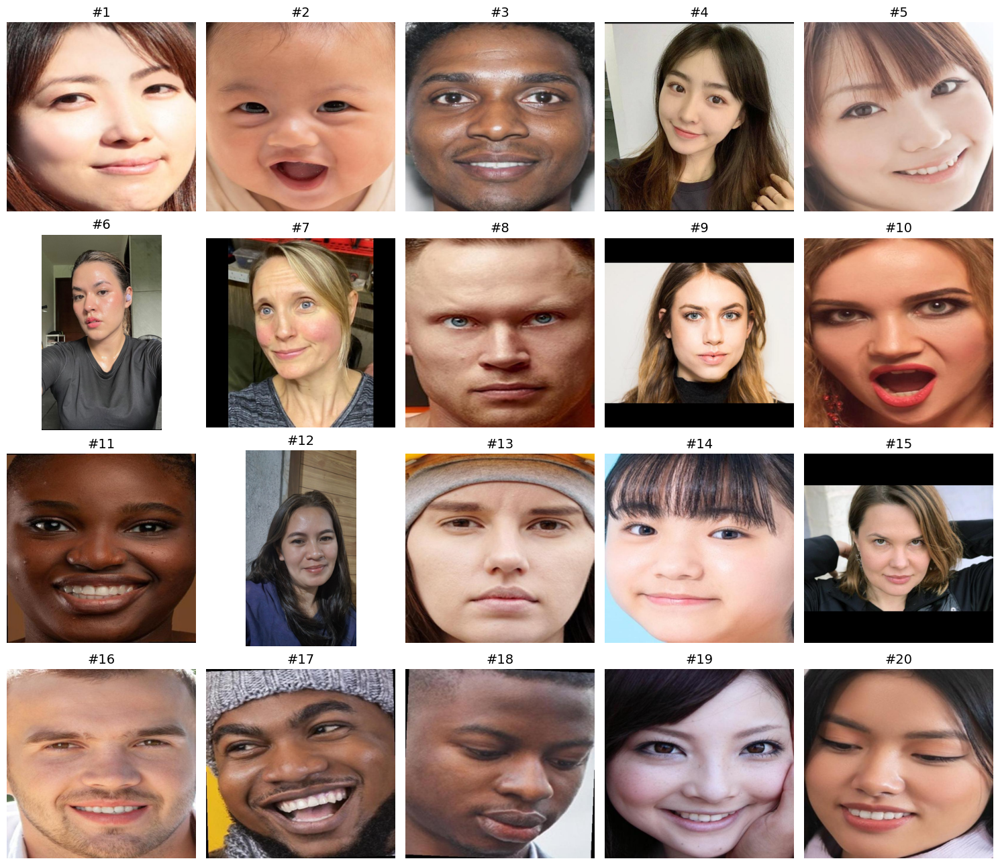

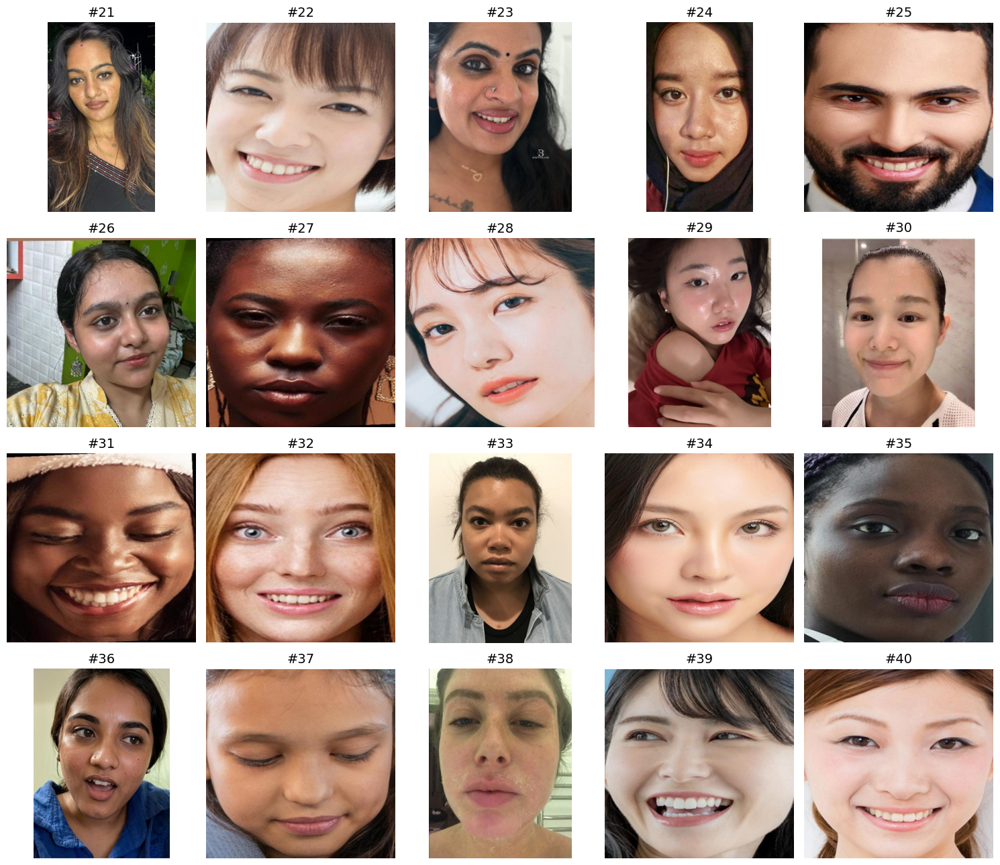

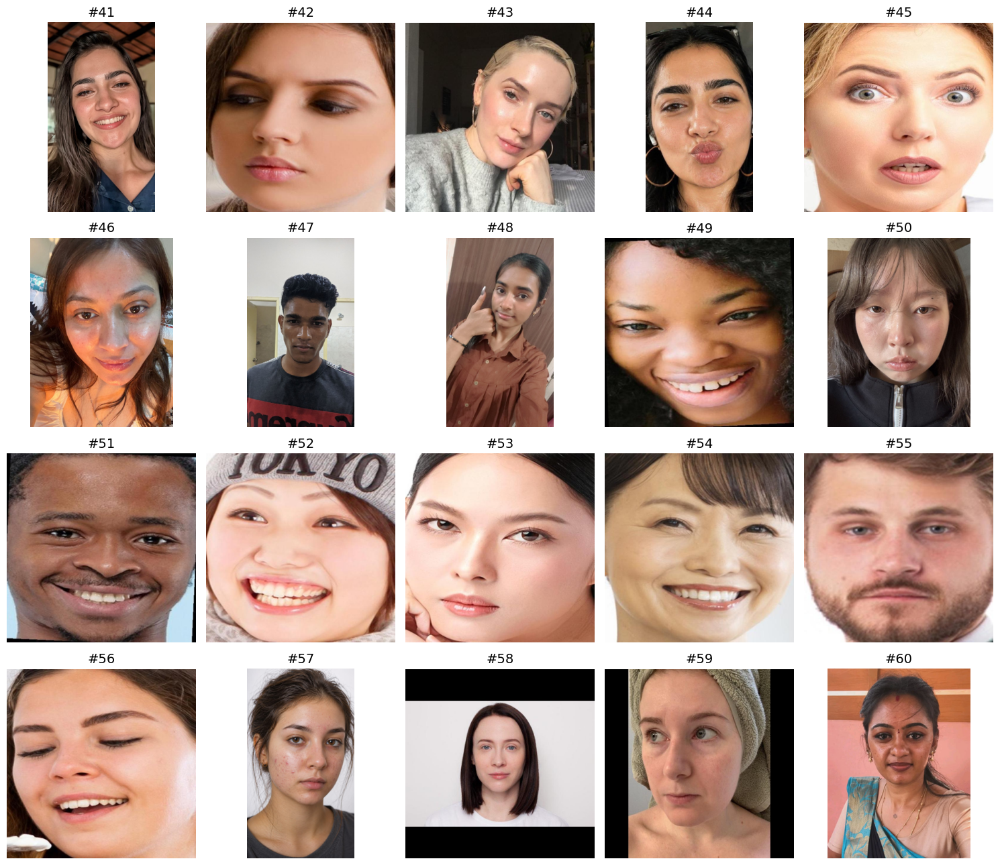

In [15]:
# Stage 5a: blind label check. Two people label the same images WITHOUT seeing the dataset label.
# Each person looks at the numbered photos below and writes one letter per photo:
#   d = dry, n = normal, o = oily, ? = can't tell
# Do it separately (paper or phone), then type both answer strings into the next cell.
LABEL_CHECK_PER_CLASS = 20
LABEL_CHECK_SEED = 7

df = pd.read_csv(WORK_DIR / "manifest_stage4b.csv")
kept = df[df["status"] == "keep"]
parts = [g.sample(min(LABEL_CHECK_PER_CLASS, len(g)), random_state=LABEL_CHECK_SEED)
         for _, g in kept.groupby("label")]
check = pd.concat(parts).sample(frac=1, random_state=LABEL_CHECK_SEED)   # mixed up, so the order gives nothing away
check["id"] = np.arange(1, len(check) + 1)
check[["id", "img_id", "label"]].rename(columns={"label": "dataset_label"}).to_csv(
    WORK_DIR / "label_check_key.csv", index=False)
print(f"{len(check)} photos, numbered 1 to {len(check)}. Do not look at the labels or file names.")

PER_FIG = 20
for start in range(0, len(check), PER_FIG):
    chunk = check.iloc[start:start + PER_FIG]
    fig, axes = plt.subplots(4, 5, figsize=(15, 13))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, r in zip(np.ravel(axes), chunk.itertuples()):
        img = load_rgb(r.path)
        img.thumbnail((360, 360))
        ax.imshow(img)
        ax.set_title(f"#{r.id}", fontsize=14)
    plt.tight_layout()
    plt.show() 

Rater A vs rater B: 95% agree on 57 photos both could label, kappa = 0.91
  (kappa: below 0.4 weak, 0.4 to 0.6 moderate, 0.6 to 0.8 good, above 0.8 very good.)
Rater A vs dataset label: 70% agree (57 labelled, 3 marked '?')


rater A,dry,normal,oily
dataset,,,
dry,7,9,2
normal,0,16,3
oily,0,3,17


Rater B vs dataset label: 72% agree (60 labelled, 0 marked '?')


rater B,dry,normal,oily
dataset,,,
dry,7,12,1
normal,0,17,3
oily,0,1,19


Two people agreeing about this often is roughly the ceiling for any model: the labels are only as clear as the photos.

14 photos where you both agree with each other but not with the dataset label.


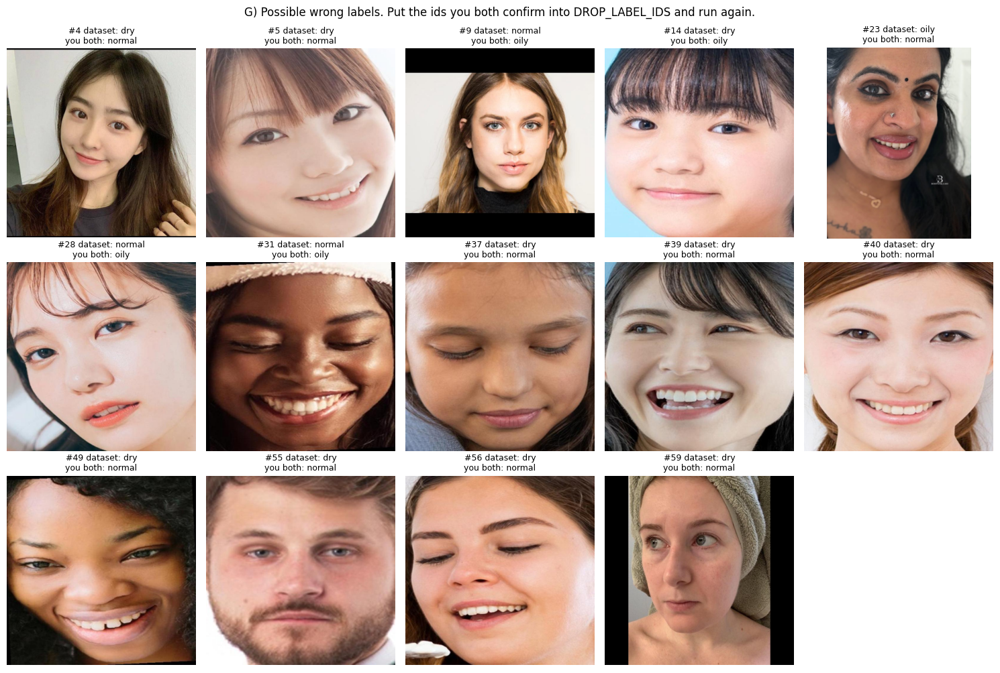

Dropped 5 images as wrongly labelled: [14, 28, 31, 49, 56]
=== after Stage 5 ===


,total,kept
label,,
dry,151,118
normal,217,186
oily,346,278
ALL,714,582


label,dry,normal,oily
drop_reason,,,
duplicate,2,3,21
duplicate_aligned,0,1,1
head_turned,23,23,43
label_conflict,1,2,1
label_rejected,3,2,0
skin_area_cut_off,2,0,2
too_bright,1,0,0
unreadable,1,0,0


In [16]:
# Stage 5b: compare the two raters with each other and with the dataset labels.
# Paste each person's answers: one letter per photo, in photo order (1, 2, 3, ...).
#   d = dry, n = normal, o = oily, ? = can't tell
RATER_A = "n?onnonoonnodon?n?dnonnonoooododondondnnnnoonoonnodnnnnnonno"
RATER_B = "nnonnonnonnodonnnndnonnonoooododondondnnonoonooonodnnnnnonno"
# After looking at gallery G below: ids that BOTH of you agree are wrongly labelled and should be removed.
DROP_LABEL_IDS = [14, 28, 31, 49, 56]

from sklearn.metrics import cohen_kappa_score

df = pd.read_csv(WORK_DIR / "manifest_stage4b.csv")
key = pd.read_csv(WORK_DIR / "label_check_key.csv")
LETTER = {"d": "dry", "n": "normal", "o": "oily", "?": None}

if not (RATER_A and RATER_B):
    print("RATER_A / RATER_B are empty, so the label check is skipped and nothing is changed.")
    df.to_csv(WORK_DIR / "manifest_stage5.csv", index=False)
else:
    a, b = RATER_A.strip().lower().replace(" ", ""), RATER_B.strip().lower().replace(" ", "")
    assert len(a) == len(key) == len(b), f"Need {len(key)} letters each, got A={len(a)}, B={len(b)}"
    assert set(a + b) <= set(LETTER), f"Only d, n, o, ? are allowed; found {sorted(set(a + b) - set(LETTER))}"
    key["A"] = [LETTER[c] for c in a]
    key["B"] = [LETTER[c] for c in b]

    both = key.dropna(subset=["A", "B"])
    print(f"Rater A vs rater B: {(both['A'] == both['B']).mean():.0%} agree on {len(both)} photos both could label, "
          f"kappa = {cohen_kappa_score(both['A'], both['B']):.2f}")
    print("  (kappa: below 0.4 weak, 0.4 to 0.6 moderate, 0.6 to 0.8 good, above 0.8 very good.)")
    for r in ["A", "B"]:
        s = key.dropna(subset=[r])
        print(f"Rater {r} vs dataset label: {(s[r] == s['dataset_label']).mean():.0%} agree "
              f"({len(s)} labelled, {len(key) - len(s)} marked '?')")
        display(pd.crosstab(s["dataset_label"], s[r], rownames=["dataset"], colnames=[f"rater {r}"]))
    print("Two people agreeing about this often is roughly the ceiling for any model: the labels are only "
          "as clear as the photos.")

    cand = both[(both["A"] == both["B"]) & (both["A"] != both["dataset_label"])].copy()
    print(f"\n{len(cand)} photos where you both agree with each other but not with the dataset label.")
    cand.to_csv(WORK_DIR / "label_review.csv", index=False)
    if len(cand):
        merged = cand.merge(df[["img_id", "path"]], on="img_id")
        fig, axes = plt.subplots(math.ceil(len(merged) / 5), 5, figsize=(15, 3.4 * math.ceil(len(merged) / 5)))
        for ax in np.ravel(axes):
            ax.axis("off")
        for ax, r in zip(np.ravel(axes), merged.itertuples()):
            img = load_rgb(r.path)
            img.thumbnail((360, 360))
            ax.imshow(img)
            ax.set_title(f"#{r.id} dataset: {r.dataset_label}\nyou both: {r.A}", fontsize=9)
        plt.suptitle("G) Possible wrong labels. Put the ids you both confirm into DROP_LABEL_IDS and run again.")
        plt.tight_layout()
        plt.show()

    if DROP_LABEL_IDS:
        bad = key.loc[key["id"].isin(DROP_LABEL_IDS), "img_id"]
        n = drop(df["img_id"].isin(bad), "label_rejected")
        print(f"Dropped {n} images as wrongly labelled: {sorted(DROP_LABEL_IDS)}")
    df.to_csv(WORK_DIR / "manifest_stage5.csv", index=False)
    funnel("Stage 5")

## Stage 6

In [17]:
# Stage 6: final train / validation / test split (about 71 / 14 / 14).
# - Stratified by class AND skin-tone group, so each split has the same mix.
# - Grouped by split_group, so photos of the same person never end up in two splits.
# - Sample weights are computed from the TRAIN split only.
# The seed is fixed. Do not change it after looking at results: that would be choosing a test set that
# flatters the model.
import hashlib
from sklearn.model_selection import StratifiedGroupKFold

SPLIT_SEED = 2026

df = pd.read_csv(WORK_DIR / "manifest_stage5.csv")
kept = df[df["status"] == "keep"].copy().reset_index(drop=True)
kept["tone3"] = kept["tone3"].astype(str)
kept["stratum"] = kept["label"] + "_" + kept["tone3"]

# 1 of 7 folds -> test (14.3%); then 1 of 6 folds of the rest -> validation (also 14.3% of the total)
trval_pos, test_pos = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SPLIT_SEED)
                           .split(kept, kept["stratum"], kept["split_group"]))
rest = kept.iloc[trval_pos]
tr_rel, val_rel = next(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SPLIT_SEED)
                       .split(rest, rest["stratum"], rest["split_group"]))
kept["split"] = "train"
kept.loc[kept.index[test_pos], "split"] = "test"
kept.loc[rest.index[val_rel], "split"] = "val"

# checks
grp_splits = kept.groupby("split_group")["split"].nunique()
assert (grp_splits == 1).all(), "A split group spans more than one split"
print(f"{len(kept)} images:", kept["split"].value_counts().to_dict(),
      "| every group is in exactly one split")
print("\nImages per split and class:")
display(pd.crosstab(kept["split"], kept["label"], margins=True))
print("Images per split, skin-tone group and class:")
display(pd.crosstab([kept["split"], kept["tone3"]], kept["label"]))
small = pd.crosstab([kept["split"], kept["tone3"]], kept["label"]).loc[["val", "test"]]
tiny = [(s, t, c, int(n)) for (s, t), row in small.iterrows() for c, n in row.items() if n < 5]
if tiny:
    print("NOTE: very small cells (split, tone, class, count). Accuracy for these will be noisy; "
          "report them with their counts:")
    for t in tiny:
        print("  ", t)

# train-only tone weights (same rule as Cell 14)
tr = kept["split"] == "train"
counts = pd.crosstab(kept.loc[tr, "tone3"], kept.loc[tr, "label"])
K = kept["label"].nunique()
w = kept.loc[tr].apply(lambda r: counts.loc[r["tone3"]].sum() / (K * counts.loc[r["tone3"], r["label"]]), axis=1)
w = w.clip(0.25, 4.0)
kept["sample_weight"] = 1.0
kept.loc[tr, "sample_weight"] = (w / w.mean()).round(4)
print("\nTrain-only sample weights per tone group and class:")
display(kept[tr].pivot_table(index="tone3", columns="label", values="sample_weight", aggfunc="first"))

cols = ["img_id", "rel", "path", "crop_v2_path", "label", "source", "tone3", "split_group",
        "split", "sample_weight"]
kept[cols].to_csv(WORK_DIR / "final_manifest.csv", index=False)
test_ids = sorted(kept.loc[kept["split"] == "test", "img_id"])
(WORK_DIR / "test_ids.txt").write_text("\n".join(test_ids))
print("\nSaved final_manifest.csv and test_ids.txt")
print("Test set fingerprint (write this down; it must never change):",
      hashlib.sha256("\n".join(test_ids).encode()).hexdigest()[:12])

582 images: {'train': 416, 'test': 84, 'val': 82} | every group is in exactly one split

Images per split and class:


label,dry,normal,oily,All
split,,,,
test,17,27,40,84
train,86,132,198,416
val,15,27,40,82
All,118,186,278,582


Images per split, skin-tone group and class:


label          dry  normal  oily
split tone3                     
test  darker     3       7     8
      lighter   11      15     9
      medium     3       5    23
train darker    15      27    63
      lighter   55      85    43
      medium    16      20    92
val   darker     2       7     9
      lighter    8      14    13
      medium     5       6    18

NOTE: very small cells (split, tone, class, count). Accuracy for these will be noisy; report them with their counts:
   ('val', 'darker', 'dry', 2)
   ('test', 'darker', 'dry', 3)
   ('test', 'medium', 'dry', 3)

Train-only sample weights per tone group and class:


label,dry,normal,oily
tone3,,,
darker,2.3333,1.2963,0.5556
lighter,1.1091,0.7176,1.4186
medium,2.6667,2.1333,0.4638



Saved final_manifest.csv and test_ids.txt
Test set fingerprint (write this down; it must never change): 1e44d55d3d43


## Stage 7

device: cuda
{'train': 416, 'test': 84, 'val': 82} | classes: ['dry', 'normal', 'oily']
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 116MB/s] 


head epoch  1/8  loss 0.973  val balanced acc 0.378  (3s)  <- best
head epoch  2/8  loss 0.812  val balanced acc 0.384  (2s)  <- best
head epoch  3/8  loss 0.772  val balanced acc 0.421  (2s)  <- best
head epoch  4/8  loss 0.730  val balanced acc 0.453  (2s)  <- best
head epoch  5/8  loss 0.660  val balanced acc 0.394  (2s)
head epoch  6/8  loss 0.711  val balanced acc 0.445  (2s)
head epoch  7/8  loss 0.705  val balanced acc 0.493  (2s)  <- best
head epoch  8/8  loss 0.654  val balanced acc 0.502  (2s)  <- best
finetune epoch  1/18  loss 0.599  val balanced acc 0.636  (2s)  <- best
finetune epoch  2/18  loss 0.518  val balanced acc 0.637  (2s)  <- best
finetune epoch  3/18  loss 0.360  val balanced acc 0.672  (2s)  <- best
finetune epoch  4/18  loss 0.364  val balanced acc 0.693  (2s)  <- best
finetune epoch  5/18  loss 0.351  val balanced acc 0.706  (2s)  <- best
finetune epoch  6/18  loss 0.312  val balanced acc 0.748  (2s)  <- best
finetune epoch  7/18  loss 0.307  val balanced acc

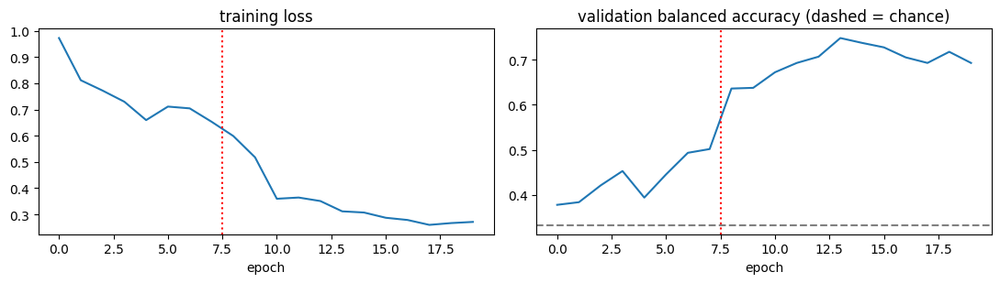

Saved mobilenetv2_skintype.pt and train_history.csv


In [18]:
# Stage 7: train MobileNetV2 on the masked skin crops.
# Two phases: (1) train only the new head, (2) fine-tune the last blocks at a low learning rate.
# Sample weights (skin tone) and class weights are both applied; the test split is never touched here.
import copy
import json
import random
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2

SEED = 2026
BATCH = 32
EPOCHS_HEAD = 8
EPOCHS_FT = 18
LR_HEAD = 1e-3
LR_FT = 1e-4
FT_FROM_BLOCK = 11          # unfreeze features[11:] in phase 2
LABEL_SMOOTH = 0.05
EARLY_STOP = 6              # stop if validation balanced accuracy has not improved for this many epochs
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

man = pd.read_csv(WORK_DIR / "final_manifest.csv")
CLASSES = sorted(man["label"].unique())
C2I = {c: i for i, c in enumerate(CLASSES)}
print({s: int(n) for s, n in man["split"].value_counts().items()}, "| classes:", CLASSES)

# Augmentation: geometry and mild brightness only. No hue/saturation changes and no sharpening,
# because colour, shine and texture are the actual signal.
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=7, translate=(0.04, 0.04), scale=(0.93, 1.07),
                            interpolation=transforms.InterpolationMode.BILINEAR, fill=sp.FILL),
    transforms.ColorJitter(brightness=0.15, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.08), value=0.0),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class CropDataset(Dataset):
    def __init__(self, frame, tf):
        self.rows = frame.reset_index(drop=True)
        self.tf = tf

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows.iloc[i]
        img = Image.open(r["crop_v2_path"]).convert("RGB")
        return self.tf(img), C2I[r["label"]], float(r["sample_weight"]), i


def loader(split, train):
    frame = man[man["split"] == split]
    ds = CropDataset(frame, train_tf if train else eval_tf)
    if train:
        # Sampling by tone weight x inverse class size: balances classes and tone groups together.
        cls_w = frame["label"].map(1.0 / frame["label"].value_counts()).to_numpy()
        w = torch.as_tensor(frame["sample_weight"].to_numpy() * cls_w, dtype=torch.double)
        sampler = WeightedRandomSampler(w, num_samples=len(frame), replacement=True)
        return DataLoader(ds, batch_size=BATCH, sampler=sampler, num_workers=2, drop_last=True), frame
    return DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=2), frame


train_dl, train_frame = loader("train", True)
val_dl, val_frame = loader("val", False)

model = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.last_channel, len(CLASSES)))
model = model.to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)


@torch.no_grad()
def evaluate(dl):
    model.eval()
    probs, ys, idx = [], [], []
    for x, y, _, i in dl:
        p = torch.softmax(model(x.to(device)), dim=1).cpu()
        probs.append(p); ys.append(y); idx.append(i)
    probs = torch.cat(probs).numpy(); ys = torch.cat(ys).numpy(); idx = torch.cat(idx).numpy()
    pred = probs.argmax(1)
    return balanced_accuracy_score(ys, pred), probs, ys, pred, idx


def run_phase(name, epochs, lr, params, history):
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, epochs))
    best = {"score": -1, "state": None, "epoch": -1}
    stale = 0
    for ep in range(1, epochs + 1):
        model.train()
        tot = n = 0
        t0 = time.time()
        for x, y, w, _ in train_dl:
            x, y, w = x.to(device), y.to(device), w.to(device).float()
            opt.zero_grad()
            losses = nn.functional.cross_entropy(model(x), y, label_smoothing=LABEL_SMOOTH, reduction="none")
            loss = (losses * w).sum() / w.sum()
            loss.backward()
            opt.step()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        val_ba, *_ = evaluate(val_dl)
        history.append({"phase": name, "epoch": ep, "train_loss": tot / max(n, 1), "val_balanced_acc": val_ba})
        flag = ""
        if val_ba > best["score"]:
            best = {"score": val_ba, "state": copy.deepcopy(model.state_dict()), "epoch": len(history)}
            stale = 0; flag = "  <- best"
        else:
            stale += 1
        print(f"{name} epoch {ep:2d}/{epochs}  loss {tot / max(n, 1):.3f}  val balanced acc {val_ba:.3f}"
              f"  ({time.time() - t0:.0f}s){flag}")
        if stale >= EARLY_STOP:
            print(f"  no improvement for {EARLY_STOP} epochs, stopping this phase")
            break
    return best


history = []
for p in model.features.parameters():
    p.requires_grad = False
best = run_phase("head", EPOCHS_HEAD, LR_HEAD, model.classifier.parameters(), history)
if best["state"]:
    model.load_state_dict(best["state"])

for m in model.features[FT_FROM_BLOCK:]:
    for p in m.parameters():
        p.requires_grad = True
best_ft = run_phase("finetune", EPOCHS_FT, LR_FT,
                    [p for p in model.parameters() if p.requires_grad], history)
if best_ft["score"] > best["score"]:
    best = best_ft
model.load_state_dict(best["state"])
print(f"\nBest validation balanced accuracy: {best['score']:.3f} (history row {best['epoch']})")

hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(hist["train_loss"]); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["val_balanced_acc"]); ax[1].axhline(1 / len(CLASSES), ls="--", c="grey")
ax[1].set_title("validation balanced accuracy (dashed = chance)"); ax[1].set_xlabel("epoch")
for i, p in enumerate(hist["phase"]):
    if i and p != hist["phase"][i - 1]:
        for a in ax:
            a.axvline(i - 0.5, c="red", ls=":")
plt.tight_layout(); plt.show()

cfg_path = WORK_DIR / "preprocess_config.json"
pre_cfg = json.loads(cfg_path.read_text()) if cfg_path.exists() else {}
if not pre_cfg:
    print("WARNING: preprocess_config.json not found; the checkpoint will not record the preprocessing "
          "settings the backend must copy.")
torch.save({"state_dict": model.state_dict(), "classes": CLASSES, "preprocess": pre_cfg,
            "val_balanced_acc": best["score"], "seed": SEED},
           WORK_DIR / "mobilenetv2_skintype.pt")
hist.to_csv(WORK_DIR / "train_history.csv", index=False)
print("Saved mobilenetv2_skintype.pt and train_history.csv")


===== VALIDATION: balanced accuracy 0.748 (chance 0.333, 82 images) =====
              precision    recall  f1-score   support

         dry      0.522     0.800     0.632        15
      normal      0.737     0.519     0.609        27
        oily      0.925     0.925     0.925        40

    accuracy                          0.768        82
   macro avg      0.728     0.748     0.722        82
weighted avg      0.789     0.768     0.767        82

Confusion matrix (rows = true, columns = predicted):


,dry,normal,oily
dry,12,2,1
normal,11,14,2
oily,0,3,37


Accuracy by tone3 (small n means a noisy number):


,n,accuracy
tone3,,
darker,18,0.778
lighter,35,0.657
medium,29,0.897


Accuracy by source (small n means a noisy number):


,n,accuracy
source,,
web,82,0.768


... (7 outputs left out)

,n,accuracy
source,,
web,84,0.738


Accuracy by skin tone and class:


n  accuracy
tone3   label               
darker  dry      3     0.667
        normal   7     0.571
        oily     8     0.875
lighter dry     11     0.727
        normal  15     0.333
        oily     9     0.778
medium  dry      3     1.000
        normal   5     0.600
        oily    23     1.000


How to read this:
  chance                     0.333
  validation balanced acc    0.748
  test balanced acc          0.711
  A large gap between validation and test usually means the splits are small, not that something broke.


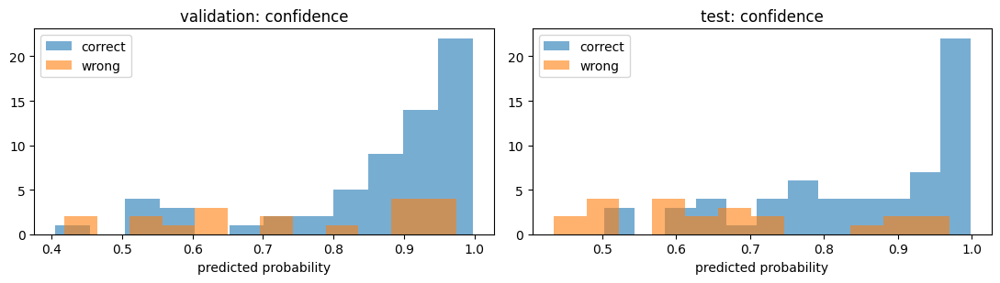

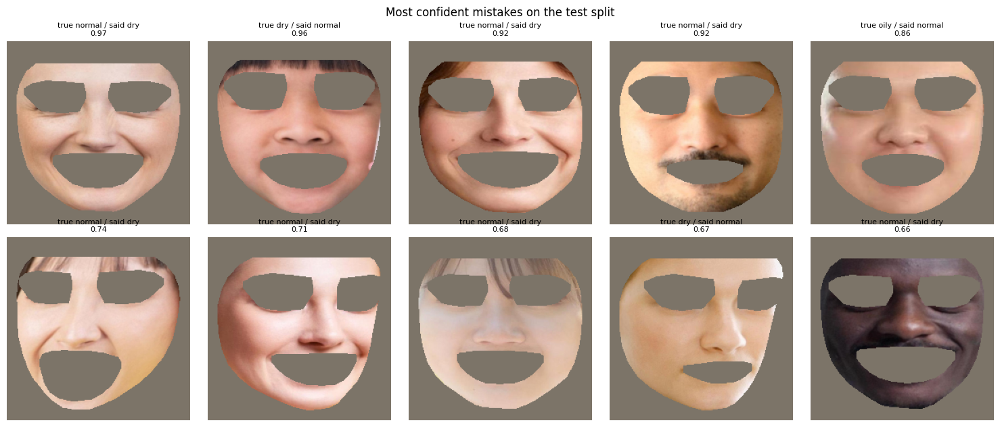

Saved test_predictions.csv


In [19]:
# Stage 8: evaluate on validation, then once on the untouched test split.
# Reports per class, per skin-tone group and per source, so a good overall number cannot hide a
# model that only works for one group.
from sklearn.metrics import classification_report, confusion_matrix

RATER_AGREEMENT = None   # put your two-rater agreement here (e.g. 0.74) once Cell 16 has run

test_dl, test_frame = loader("test", False)


def report(split_name, dl, frame):
    ba, probs, ys, pred, idx = evaluate(dl)
    f = frame.reset_index(drop=True).iloc[idx].copy()
    f["pred"] = [CLASSES[p] for p in pred]
    f["correct"] = f["pred"] == f["label"]
    f["confidence"] = probs.max(1)
    print(f"\n===== {split_name}: balanced accuracy {ba:.3f} (chance {1 / len(CLASSES):.3f}, "
          f"{len(f)} images) =====")
    print(classification_report(f["label"], f["pred"], digits=3, zero_division=0))
    print("Confusion matrix (rows = true, columns = predicted):")
    display(pd.DataFrame(confusion_matrix(f["label"], f["pred"], labels=CLASSES),
                         index=CLASSES, columns=CLASSES))
    for by in ["tone3", "source"]:
        t = f.groupby(by).agg(n=("correct", "size"), accuracy=("correct", "mean")).round(3)
        print(f"Accuracy by {by} (small n means a noisy number):")
        display(t)
    t = f.groupby(["tone3", "label"]).agg(n=("correct", "size"), accuracy=("correct", "mean")).round(3)
    print("Accuracy by skin tone and class:")
    display(t)
    return ba, f


val_ba, val_f = report("VALIDATION", val_dl, val_frame)
test_ba, test_f = report("TEST (untouched until now)", test_dl, test_frame)

print("\nHow to read this:")
print(f"  chance                     {1 / len(CLASSES):.3f}")
print(f"  validation balanced acc    {val_ba:.3f}")
print(f"  test balanced acc          {test_ba:.3f}")
if RATER_AGREEMENT:
    print(f"  two humans agreeing        {RATER_AGREEMENT:.3f}  <- realistic ceiling for this data")
print("  A large gap between validation and test usually means the splits are small, not that something broke.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, (name, f) in zip(ax, [("validation", val_f), ("test", test_f)]):
    lo, hi = float(f["confidence"].min()), float(f["confidence"].max())
    bins = np.linspace(lo - 0.01, hi + 0.01, 13) if hi - lo < 1e-6 else 12
    for ok, lbl in [(True, "correct"), (False, "wrong")]:
        vals = f.loc[f["correct"] == ok, "confidence"]
        if len(vals):
            a.hist(vals, bins=bins, alpha=0.6, label=lbl)
    a.set_title(f"{name}: confidence"); a.legend(); a.set_xlabel("predicted probability")
plt.tight_layout(); plt.show()

wrong = test_f[~test_f["correct"]].sort_values("confidence", ascending=False).head(10)
if len(wrong):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
    for a in np.ravel(axes):
        a.axis("off")
    for a, r in zip(np.ravel(axes), wrong.itertuples()):
        a.imshow(Image.open(r.crop_v2_path))
        a.set_title(f"true {r.label} / said {r.pred}\n{r.confidence:.2f}", fontsize=8)
    plt.suptitle("Most confident mistakes on the test split")
    plt.tight_layout(); plt.show()

test_f.to_csv(WORK_DIR / "test_predictions.csv", index=False)
print("Saved test_predictions.csv")

In [20]:
# Does a milder blur help dry vs normal? Rebuild crops at a higher sharpness target and retrain.
# The split and the test set are untouched: only the crop pixels change.
ABLATION_PERCENTILE = 50     # 20 was the original; 50 keeps much more skin texture

import json
importlib.reload(sp)
man_v3 = pd.read_csv(WORK_DIR / "final_manifest.csv")
CROP_DIR_V3 = WORK_DIR / "crops_v3"
CROP_DIR_V3.mkdir(exist_ok=True)
landmarks = np.load(WORK_DIR / "landmarks.npz")
s4b = pd.read_csv(WORK_DIR / "manifest_stage4b.csv")

train_ids = set(man_v3.loc[man_v3["split"] == "train", "img_id"])
tr_sharp = s4b[s4b["img_id"].isin(train_ids)]
target_v3 = float(tr_sharp.groupby("label")["sharpness_raw_v2"].quantile(ABLATION_PERCENTILE / 100).min())
print(f"new sharpness target = {target_v3:.1f} (was 53.2)")

paths = []
for r in tqdm(man_v3.itertuples(), total=len(man_v3), desc="rebuilding crops"):
    masked = sp.preprocess(load_rgb(r.path), landmarks[r.img_id].astype(np.float32),
                           sharpness_target=target_v3)
    p = CROP_DIR_V3 / f"{r.img_id}.png"
    masked.save(p)
    paths.append(str(p))
man_v3["crop_v2_path"] = paths
man_v3.to_csv(WORK_DIR / "final_manifest_v3.csv", index=False)
print("Saved final_manifest_v3.csv")

new sharpness target = 94.0 (was 53.2)


rebuilding crops:   0%|          | 0/582 [00:00<?, ?it/s]

Saved final_manifest_v3.csv


In [21]:
man = pd.read_csv(WORK_DIR / "final_manifest_v3.csv")
train_dl, train_frame = loader("train", True)
val_dl, val_frame = loader("val", False)

model = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.last_channel, len(CLASSES)))
model = model.to(device)

history_v3 = []
for p in model.features.parameters():
    p.requires_grad = False
best_v3 = run_phase("head_v3", EPOCHS_HEAD, LR_HEAD, model.classifier.parameters(), history_v3)
if best_v3["state"]:
    model.load_state_dict(best_v3["state"])
for m in model.features[FT_FROM_BLOCK:]:
    for p in m.parameters():
        p.requires_grad = True
best_ft_v3 = run_phase("finetune_v3", EPOCHS_FT, LR_FT,
                       [p for p in model.parameters() if p.requires_grad], history_v3)
if best_ft_v3["score"] > best_v3["score"]:
    best_v3 = best_ft_v3
model.load_state_dict(best_v3["state"])
print(f"\nv3 (milder blur, target={target_v3:.1f}) best validation balanced accuracy: {best_v3['score']:.3f}")
print(f"v2 (original, target=53.2) was:                                           0.748")

head_v3 epoch  1/8  loss 0.929  val balanced acc 0.289  (2s)  <- best
head_v3 epoch  2/8  loss 0.793  val balanced acc 0.373  (2s)  <- best
head_v3 epoch  3/8  loss 0.723  val balanced acc 0.417  (2s)  <- best
head_v3 epoch  4/8  loss 0.758  val balanced acc 0.531  (2s)  <- best
head_v3 epoch  5/8  loss 0.672  val balanced acc 0.434  (2s)
head_v3 epoch  6/8  loss 0.685  val balanced acc 0.514  (2s)
head_v3 epoch  7/8  loss 0.680  val balanced acc 0.503  (2s)
head_v3 epoch  8/8  loss 0.670  val balanced acc 0.500  (2s)
finetune_v3 epoch  1/18  loss 0.630  val balanced acc 0.610  (2s)  <- best
finetune_v3 epoch  2/18  loss 0.503  val balanced acc 0.646  (2s)  <- best
finetune_v3 epoch  3/18  loss 0.433  val balanced acc 0.633  (2s)
finetune_v3 epoch  4/18  loss 0.369  val balanced acc 0.652  (2s)  <- best
finetune_v3 epoch  5/18  loss 0.317  val balanced acc 0.687  (2s)  <- best
finetune_v3 epoch  6/18  loss 0.314  val balanced acc 0.687  (2s)
finetune_v3 epoch  7/18  loss 0.284  val bal

In [22]:
# Run this once. Whichever had the higher validation score becomes the final model, and only
# that one touches the test split, here, one time.
USE_V3 = best_v3["score"] > 0.748   # flip manually if you'd rather keep the original for another reason

if USE_V3:
    final_manifest_path = WORK_DIR / "final_manifest_v3.csv"
    final_sharpness_target = target_v3
    final_state = best_v3["state"]
    print(f"Keeping v3 (milder blur): val {best_v3['score']:.3f} beat v2's 0.748")
else:
    final_manifest_path = WORK_DIR / "final_manifest.csv"
    final_sharpness_target = 53.21
    man = pd.read_csv(final_manifest_path)
    val_dl, val_frame = loader("val", False)
    model.load_state_dict(torch.load(WORK_DIR / "mobilenetv2_skintype.pt", weights_only=False)["state_dict"])
    final_state = model.state_dict()
    print(f"Keeping v2 (original): 0.748 >= v3's {best_v3['score']:.3f}")

model.load_state_dict(final_state)
test_dl, test_frame = loader("test", False)
RATER_AGREEMENT = 0.71   # your rater-vs-dataset-label agreement
test_ba, test_f = report("FINAL TEST (run once)", test_dl, test_frame)
print(f"\nFINAL test balanced accuracy: {test_ba:.3f}  (human-vs-label ceiling: ~{RATER_AGREEMENT:.2f})")

pre_cfg = {"preprocess_version": sp.VERSION, "normalize_aspect": True,
          "sharpness_target": round(final_sharpness_target, 2)}
torch.save({"state_dict": model.state_dict(), "classes": CLASSES, "preprocess": pre_cfg,
            "val_balanced_acc": max(best_v3["score"], 0.748), "test_balanced_acc": test_ba,
            "rater_agreement": RATER_AGREEMENT, "seed": SEED},
           WORK_DIR / "mobilenetv2_skintype_final.pt")
(WORK_DIR / "preprocess_config.json").write_text(json.dumps(pre_cfg, indent=2))
test_f.to_csv(WORK_DIR / "test_predictions_final.csv", index=False)
print("\nSaved mobilenetv2_skintype_final.pt and preprocess_config.json — this is the model to download.")

Keeping v2 (original): 0.748 >= v3's 0.725

===== FINAL TEST (run once): balanced accuracy 0.711 (chance 0.333, 84 images) =====
              precision    recall  f1-score   support

         dry      0.481     0.765     0.591        17
      normal      0.667     0.444     0.533        27
        oily      0.949     0.925     0.937        40

    accuracy                          0.738        84
   macro avg      0.699     0.711     0.687        84
weighted avg      0.763     0.738     0.737        84

Confusion matrix (rows = true, columns = predicted):


,dry,normal,oily
dry,13,4,0
normal,13,12,2
oily,1,2,37


Accuracy by tone3 (small n means a noisy number):


,n,accuracy
tone3,,
darker,18,0.722
lighter,35,0.571
medium,31,0.935


Accuracy by source (small n means a noisy number):


,n,accuracy
source,,
web,84,0.738


Accuracy by skin tone and class:


n  accuracy
tone3   label               
darker  dry      3     0.667
        normal   7     0.571
        oily     8     0.875
lighter dry     11     0.727
        normal  15     0.333
        oily     9     0.778
medium  dry      3     1.000
        normal   5     0.600
        oily    23     1.000


FINAL test balanced accuracy: 0.711  (human-vs-label ceiling: ~0.71)

Saved mobilenetv2_skintype_final.pt and preprocess_config.json — this is the model to download.
